# Week 7: Text and Multimodal AI (Project 2)

| | |
|---|---|
| **Author** | *(Bilawal Makhdoom)* |
| **Date** | 2 November 2026 |
| **Course** | Introduction to Applied AI |
| **Domain** | Brain-tumour MRI (Week 6 model) |
| **Environment** | Kaggle notebook, Python 3.13, spaCy 3.8.16, PyTorch 2.11.0 (CUDA 12.8 build) |

## Objective

Project 2 gives the Week 6 image model the ability to *read*. This notebook builds the text side (TF-IDF, a spam classifier, named-entity recognition, regular expressions, OCR repair) and then combines image and text evidence into one transparent, privacy-safe case record. Every component is **measured**, and each result in the write-ups can be checked against the printed output of its cell.

## Results at a glance

| Part | Topic | Key idea | Measured result (this run) |
|---|---|---|---|
| 1 | TF-IDF by hand | smooth IDF, L2 norm, cosine | hand = scikit-learn; cosine(d2, d3) = **0.544** |
| 2 | SMS spam: word vs character n-grams | logistic regression, macro-F1 | macro-F1 **0.974** (word) vs **0.982** (char) |
| 3 | NER against a gold set, then entity ruler | entity-level P, R, F1 | provided set **0.516 → 0.875**; my held-out set **0.556 → 0.811** |
| 4 | Regex fields with negative tests | pattern tests, word boundaries | **5/5** lab tests, **8/8** domain tests (5 negative) |
| 5 | Character error rate and OCR repair | CER = (S + D + I) / N | lab pairs 0.062, 0.059, 0.143 → 0.000; invoice 0.000 |
| 6 | Image + text case record with privacy | late fusion, masking first | REFER, P(tumor) = 0.996, no PII in the JSON |
| 7 | Check Your Understanding | | six answers with working |

## How to run this notebook

| Setting / input | Value |
|---|---|
| Internet | **On** (EasyOCR downloads about 100 MB on first use) |
| SMS dataset | `/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv` |
| Week 6 model | `/kaggle/input/datasets/bilawalmakhdoom/week6-model-pt/week6_model.pt` |
| MRI images (Part 6) | `/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset` (add with **Add Input**) |

Every path is first tried exactly and then searched for under `/kaggle/input`, so a slightly different folder name does not break the notebook. A path that points to a **folder** is also accepted: the helper looks for the file inside it.

**Layout of every section:** a heading and description *before* the cell (what it does and why), the cell with its real output, then a **Calculations** or **Reading the output** block *after* it that re-derives the printed numbers by hand.

## Contents

1. Formula sheet and setup
2. Part 1: TF-IDF by hand
3. Part 2: Text classification (SMS spam)
4. Part 3: Named entity recognition, measured
5. Part 4: Regex fields with negative tests
6. Part 5: Character error rate and OCR repair
7. Part 6: Image + text case record
8. Check Your Understanding
9. Summary, limitations and next steps

## Key formulas (short version)

Only the few formulas that the results depend on. Each one is written in plain text.

| Name | Formula |
|---|---|
| Smooth IDF | `idf = ln((1 + N) / (1 + df)) + 1` |
| TF-IDF weight | `weight = tf * idf`, then divide by the vector length (L2 norm) |
| Cosine similarity | dot product of two length-1 vectors |
| Precision, recall, F1 | `P = TP/(TP+FP)`, `R = TP/(TP+FN)`, `F1 = 2PR/(P+R)` |
| Character error rate | `CER = (substitutions + deletions + insertions) / reference length` |
| Late fusion | `p = w * p_image + (1 - w) * p_text` |

## Setup: imports, spaCy and helper functions

**What this cell does.** Loads every library in one place (so a failing import cannot break a later cell), loads the spaCy English model `en_core_web_sm` (downloading it if missing) and defines two helpers:

- `show(md_text)` renders a markdown string as cell output (used by the "Write it" cells);
- `first_existing(primary, pattern)` uses the exact Kaggle path if it exists, looks inside it if it is a folder, and otherwise searches `/kaggle/input`.

**Expected output:** the spaCy and PyTorch versions.

In [1]:
import os, re, sys, json, glob, subprocess
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt 
import spacy
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageDraw, ImageFont
from torchvision import models, transforms
from IPython.display import display, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, f1_score)

try:
    nlp = spacy.load('en_core_web_sm')           # preinstalled on Kaggle
except OSError:                                   # model missing: download once
    subprocess.run([sys.executable, '-m', 'spacy', 'download', 'en_core_web_sm'],
                   check=True)
    nlp = spacy.load('en_core_web_sm')
print('spaCy', spacy.__version__, '| torch', torch.__version__)

def show(md_text):
    """Render a markdown string as the cell output."""
    display(Markdown(md_text))

def first_existing(primary, pattern, what='file'):
    """Use the exact file path if it exists; if a folder is given, look inside it;
    otherwise search /kaggle/input for the pattern."""
    if os.path.isfile(primary):
        return primary
    if os.path.isdir(primary):
        ext = os.path.splitext(pattern)[1]
        inside = [p for p in sorted(glob.glob(os.path.join(primary, '**', '*' + ext),
                                              recursive=True)) if os.path.isfile(p)]
        if inside:
            print(f'{what}: {primary} is a folder, using {inside[0]}')
            return inside[0]
    hits = [p for p in sorted(glob.glob(pattern, recursive=True)) if os.path.isfile(p)]
    if hits:
        print(f'{what}: {primary} not found, using {hits[0]}')
        return hits[0]
    raise FileNotFoundError(
        f'{what} not found. Add it with "Add Input" and copy the exact path '
        f'(tried {primary} and {pattern}).')

spaCy 3.8.16 | torch 2.11.0+cu128


**Reading the output.** The session reports `spaCy 3.8.16 | torch 2.11.0+cu128`. The `+cu128` suffix means this PyTorch build supports CUDA 12.8, so the session can use a GPU; the models in this notebook are small and run on CPU just as well.

---
# Part 1: TF-IDF by Hand

**Goal.** Before trusting a library, reproduce it. This cell builds the TF-IDF table for three tiny messages with scikit-learn, recomputes document d1 by hand and asserts that the two agree.

**The three messages:** d1 = "win free cash now", d2 = "call me now", d3 = "free call now" (N = 3).

**Formula used:** `idf = ln((1 + N) / (1 + df)) + 1`, then each document vector is scaled to length 1.

Words that appear in many documents get a low IDF (they cannot tell documents apart); rare words get a boost. The `+1` keeps a word that appears everywhere from getting weight 0.

In [2]:
docs = ['win free cash now', 'call me now', 'free call now']
vec = TfidfVectorizer()                 # smooth idf + L2 normalization
X = vec.fit_transform(docs)
table = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out(),
                     index=['d1', 'd2', 'd3'])
print(table.round(3))

# Reproduce d1 by hand: idf = ln((1 + N) / (1 + df)) + 1
N = 3
idf = {'win': np.log(4 / 2) + 1, 'free': np.log(4 / 3) + 1,
       'cash': np.log(4 / 2) + 1, 'now': np.log(4 / 4) + 1}
v = np.array(list(idf.values()))       # tf = 1 for each word in d1
by_hand = {w: round(float(x), 3) for w, x in zip(idf, v / np.linalg.norm(v))}
print('by hand d1:', by_hand)
print('raw idf   :', {w: round(float(x), 4) for w, x in idf.items()})

lib_d1 = {w: round(float(table.loc['d1', w]), 3) for w in idf}
assert lib_d1 == by_hand, 'hand calculation and scikit-learn disagree'
print('hand == library for d1: OK')

# Cosine similarity d2 vs d3 (vectors already have length 1, so just the dot product)
A = X.toarray()
cos_d2_d3 = float(A[1] @ A[2])
print(f'cosine(d2, d3) = {cos_d2_d3:.3f}   (slide 10: 0.54)')

     call   cash   free    me    now    win
d1  0.000  0.584  0.445  0.00  0.345  0.584
d2  0.548  0.000  0.000  0.72  0.425  0.000
d3  0.620  0.000  0.620  0.00  0.481  0.000
by hand d1: {'win': 0.584, 'free': 0.445, 'cash': 0.584, 'now': 0.345}
raw idf   : {'win': 1.6931, 'free': 1.2877, 'cash': 1.6931, 'now': 1.0}
hand == library for d1: OK
cosine(d2, d3) = 0.544   (slide 10: 0.54)


#### Calculations: Part 1 (checked against the printed output)

**Step 1: smooth IDF** (N = 3, so 1 + N = 4)

| Word | df | ln(4 / (1 + df)) + 1 | idf |
|---|---|---|---|
| win | 1 | ln(2) + 1 | **1.6931** |
| free | 2 | ln(4/3) + 1 | **1.2877** |
| cash | 1 | ln(2) + 1 | **1.6931** |
| call | 2 | ln(4/3) + 1 | **1.2877** |
| me | 1 | ln(2) + 1 | **1.6931** |
| now | 3 | ln(1) + 1 | **1.0000** |

"now" is in all three messages, so it gets the lowest weight. This matches the printed `raw idf`.

**Step 2: d1 by hand.** Each word appears once, so the raw vector equals the idf values (1.6931, 1.2877, 1.6931, 1.0). Its length is 2.8969, and dividing by it gives:

| Word | Value | Printed |
|---|---|---|
| win | 0.5845 | **0.584** |
| free | 0.4445 | **0.445** |
| cash | 0.5845 | **0.584** |
| now | 0.3452 | **0.345** |

These equal the scikit-learn row for d1 (the cell prints `hand == library for d1: OK`).

**Step 3: cosine similarity.** The vectors have length 1, so cosine is just the dot product over shared words. d2 and d3 share "call" (0.548 x 0.620 = 0.340) and "now" (0.425 x 0.481 = 0.204), so **cos(d2, d3) = 0.544**, as printed. The other pairs are lower: d1 and d3 give 0.44, and d1 and d2 give 0.15 (only "now" is shared).

**Interpretation.** "call" adds 0.340 to the d2/d3 similarity but "now" only 0.204, because "now" is in every message. That is why IDF matters for search, duplicate detection and the retrieval step planned for Week 10.

---
# Part 2: Text Classification (SMS Spam)

Week 2's logistic regression, now with words as features: `TF-IDF → Logistic Regression` is a strong, fast, interpretable baseline for short texts.

### Task 2.1: Load and inspect the SMS Spam Collection

**What this cell does.** Reads `spam.csv` (the file is Latin-1, not UTF-8, hence `encoding='latin-1'`), keeps the label and text columns, makes a 0/1 target `y` (spam = 1) and prints the class balance. It also prints the accuracy of the useless classifier that always says "ham", the number any real model must beat.


In [3]:
path = first_existing(
    '/kaggle/input/datasets/uciml/sms-spam-collection-dataset/spam.csv',
    '/kaggle/input/**/spam.csv', what='SMS dataset')
sms = pd.read_csv(path, encoding='latin-1')[['v1', 'v2']]   # file is Latin-1, not UTF-8
sms.columns = ['label', 'text']
sms['y'] = (sms['label'] == 'spam').astype(int)
print(sms['label'].value_counts().to_string())
print(f"Spam share: {sms['y'].mean():.3f}   "
      f"'always ham' accuracy: {1 - sms['y'].mean():.3f}")

label
ham     4825
spam     747
Spam share: 0.134   'always ham' accuracy: 0.866


#### Calculations: Task 2.1

Total messages: 4825 + 747 = 5572. Spam share = 747 / 5572 = 0.134 (printed 0.134). "Always ham" accuracy = 4825 / 5572 = 0.866 (printed 0.866).

**Why accuracy is the wrong metric here.** A model that never flags anything already scores 86.6%, so I report **macro-F1** and the **spam precision and recall** instead. Both kinds of error also matter: a false negative lets a scam through, and a false positive hides a real message from a bank or a family member.

### Task 2.2: Word n-gram classifier

**What this cell does.** Splits the data 80/20 (`random_state=42`, stratified so the 13.4% spam share is the same in both parts), then trains a pipeline of `TfidfVectorizer` (words and word pairs) and `LogisticRegression`. It prints the classification report and draws the confusion matrix.

**Why each setting**

| Setting | Reason |
|---|---|
| `ngram_range=(1, 2)` | "call now" means more than "call" + "now" |
| `min_df=2` | drop words seen only once (Zipf's long tail) |
| `sublinear_tf=True` | use `1 + ln(tf)`: the 10th "free" adds little |
| `class_weight='balanced'` | spam is only 13.4%, so errors on spam are weighted up |


              precision    recall  f1-score   support

         ham      0.990     0.997     0.993       966
        spam      0.979     0.933     0.955       149

    accuracy                          0.988      1115
   macro avg      0.984     0.965     0.974      1115
weighted avg      0.988     0.988     0.988      1115



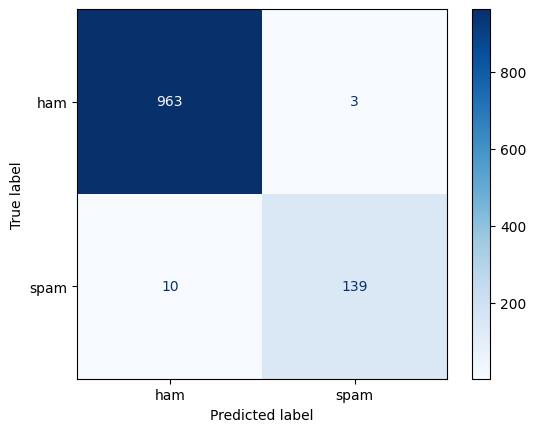

In [4]:
X_tr, X_te, y_tr, y_te = train_test_split(
    sms['text'], sms['y'], test_size=0.2, random_state=42,
    stratify=sms['y'])

word_clf = Pipeline([
    ('tfidf', TfidfVectorizer(ngram_range=(1, 2), min_df=2,
                              sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
word_clf.fit(X_tr, y_tr)
pred = word_clf.predict(X_te)
print(classification_report(y_te, pred, target_names=['ham', 'spam'],
                            digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=['ham', 'spam']).plot(cmap='Greens')
plt.show()

#### Calculations: Task 2.2 (word model)

**Split sizes.** 20% of 5572 is about 1,115 test messages (966 ham + 149 spam) and 4,457 training messages (3,859 ham + 598 spam).

**Class weights** (`balanced`): spam gets 4457 / (2 x 598) = 3.73 and ham gets 4457 / (2 x 3859) = 0.58, so a missed spam message costs about 6.5 times as much as a missed ham message during training.

**Sublinear tf example.** A word used 10 times counts as 3.30 instead of 10.

**Confusion matrix recovered from the report:**

| | Predicted ham | Predicted spam |
|---|---|---|
| **True ham (966)** | TN = 963 | FP = 3 |
| **True spam (149)** | FN = 10 | TP = 139 |

- Spam: precision = 139/142 = 0.979, recall = 139/149 = 0.933, F1 = 0.955.
- Ham: precision = 963/973 = 0.990, recall = 963/966 = 0.997, F1 = 0.993.
- Macro-F1 = (0.993 + 0.955) / 2 = **0.974**; accuracy = 1102/1115 = 0.988; errors = 3 + 10 = 13.

All of these match the printed report.

### Task 2.3: What did the word model learn?

**What this cell does.** Reads the learned weights $\mathbf{w}$ of the logistic regression and sorts them. A large positive weight pushes an n-gram toward spam; a large negative weight pushes it toward ham. The 12 most extreme on each side are saved in `top_spam` and `top_ham`.

**Idea.** The model adds up one contribution per n-gram (weight x TF-IDF value), so a high-weight word that is also frequent in the message pushes the spam score up the most.

In [5]:
tfv = word_clf.named_steps['tfidf']
coef = word_clf.named_steps['model'].coef_[0]
terms = tfv.get_feature_names_out()
order = np.argsort(coef)
top_spam = list(terms[order[-12:]][::-1])
top_ham = list(terms[order[:12]])
print('Most spam-like :', top_spam)
print('Most ham-like  :', top_ham)

Most spam-like : ['call', 'txt', 'free', 'text', 'reply', 'uk', 'to', 'www', 'mobile', 'claim', 'stop', 'your']
Most ham-like  : ['my', 'me', 'ok', 'that', 'it', 'but', 'll', 'gt', 'lt', 'can', 'what', 'da']


#### Reading the output: Task 2.3

| Direction | Top n-grams printed | Verdict |
|---|---|---|
| Spam-like | call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your | mostly sensible: calls to action, short-code replies, web and UK-number cues |
| Ham-like | my, me, ok, that, it, but, ll, gt, lt, can, what, da | personal chat words |

**Shortcut-like features.** "to" and "your" are function words; they lean spam only because spam says "to claim", "to stop" and talks to "you". **Dataset artefacts:** "gt" and "lt" are leftovers of the HTML escapes `&gt;` and `&lt;` in the ham messages, and "da" is an Indian-English chat particle. A model leaning on these would not transfer to a new message source.

**A concrete cost.** "Waiting for your call." (a ham message) scores p = 0.85, because "your" and "call" are both top spam features (it is the last row of the error table in Task 2.5).

### Task 2.4: Character n-grams and spelling tricks

**What this cell does.**

1. Trains a second pipeline that uses **character n-grams of length 2 to 5 inside word boundaries** (`char_wb`) instead of words.
2. Stores macro-F1, spam precision, spam recall, vocabulary size and the number of errors for both models in `results`.
3. Prints the full report for the character model.
4. Scores five tricky messages with both models (two from the lab, three of my own: a disguised English spam, a Roman Urdu spam and a Roman Urdu ham as a control). A message is flagged as spam when $p\ge0.5$.

**Why characters?** Misspellings such as "FR33 pr1ze" still share fragments with "free prize", and Roman Urdu has no fixed spelling ("acha", "achha", "accha"), but overlapping fragments ("ach", "cha") still match.

In [6]:
char_clf = Pipeline([
    ('tfidf', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5),
                              min_df=2, sublinear_tf=True)),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced'))])
char_clf.fit(X_tr, y_tr)

results = {}
for name, key, clf in [('word 1-2 grams', 'word', word_clf),
                       ('char 2-5 grams', 'char', char_clf)]:
    p = clf.predict(X_te)
    rep = classification_report(y_te, p, output_dict=True)
    results[key] = dict(macro_f1=f1_score(y_te, p, average='macro'),
                        prec=rep['1']['precision'], rec=rep['1']['recall'],
                        n_feat=len(clf.named_steps['tfidf'].vocabulary_),
                        n_err=int((p != y_te.values).sum()))
    print(f'{name:15s} macro-F1 {results[key]["macro_f1"]:.3f}  '
          f'features {results[key]["n_feat"]:,}')

print()
print('Character model, full report:')
print(classification_report(y_te, char_clf.predict(X_te),
                            target_names=['ham', 'spam'], digits=3))

# Robustness to spelling tricks: two from the lab, three of my own
# (disguised English spam, Roman Urdu spam, Roman Urdu ham as a control)
tricky_msgs = [
    ('W1N a FR33 pr1ze!! txt CLAIM now', 'spam'),                              # lab
    ('parso milenge, 6 baje', 'ham'),                                          # lab
    ('C0ngrats!! U w0n Rs 40000 pr1ze. Cl@im by txt 7421 now', 'spam'),         # mine
    ('Shabash! Aap ne 75000 ka inaam jeeta hai, foran 6200 par SMS karein',
     'spam'),                                                                   # mine
    ('Bhai class parso dopahar 2 baje hai, slides share kar dena', 'ham')]              # mine
msgs = [m for m, _ in tricky_msgs]
tricky_df = pd.DataFrame({
    'message': msgs, 'expected': [e for _, e in tricky_msgs],
    'word_p_spam': word_clf.predict_proba(msgs)[:, 1].round(2),
    'char_p_spam': char_clf.predict_proba(msgs)[:, 1].round(2)})
pd.set_option('display.max_colwidth', 80)
print(tricky_df.to_string())

word 1-2 grams  macro-F1 0.974  features 12,128
char 2-5 grams  macro-F1 0.982  features 36,449

Character model, full report:
              precision    recall  f1-score   support

         ham      0.993     0.998     0.995       966
        spam      0.986     0.953     0.969       149

    accuracy                          0.992      1115
   macro avg      0.989     0.975     0.982      1115
weighted avg      0.992     0.992     0.992      1115

                                                               message expected  word_p_spam  char_p_spam
0                                     W1N a FR33 pr1ze!! txt CLAIM now     spam         0.99         0.85
1                                                parso milenge, 6 baje      ham         0.19         0.15
2               C0ngrats!! U w0n Rs 40000 pr1ze. Cl@im by txt 7421 now     spam         0.81         0.81
3  Shabash! Aap ne 75000 ka inaam jeeta hai, foran 6200 par SMS karein     spam         0.36         0.52
4           Bhai

#### Calculations: Task 2.4 (character model and comparison)

**Confusion matrix recovered from the printed report:**

| | Predicted ham | Predicted spam |
|---|---|---|
| **True ham (966)** | TN = 964 | FP = 2 |
| **True spam (149)** | FN = 7 | TP = 142 |

Spam precision = 142/144 = 0.986, recall = 142/149 = 0.953, F1 = 0.969. Macro-F1 = (0.995 + 0.969) / 2 = **0.982**; accuracy = 1106/1115 = 0.992; errors = 2 + 7 = 9.

**Word vs character, side by side**

| Model | Features | Macro-F1 | Spam precision | Spam recall | Errors |
|---|---|---|---|---|---|
| word 1-2 grams | 12,128 | 0.974 | 0.979 | 0.933 | 13 |
| char_wb 2-5 grams | 36,449 | 0.982 | 0.986 | 0.953 | 9 |

The gain is 0.008 macro-F1 (only 4 messages out of 1115) for about 3 times more features. A gap this small on one split is too weak to call a real difference on clean English SMS, so the case for characters rests on **robustness**, shown by the tricky messages:

| Message | Expected | Word p(spam) | Char p(spam) |
|---|---|---|---|
| W1N a FR33 pr1ze!! txt CLAIM now | spam | 0.99 (ok) | 0.85 (ok) |
| parso milenge, 6 baje | ham | 0.19 (ok) | 0.15 (ok) |
| C0ngrats!! U w0n Rs 40000 pr1ze. Cl@im by txt 7421 now | spam | 0.81 (ok) | 0.81 (ok) |
| Shabash! Aap ne 75000 ka inaam jeeta hai... | spam | **0.36 (missed)** | 0.52 (ok, barely) |
| Bhai class parso dopahar 2 baje hai, slides share kar dena | ham | 0.13 (ok) | 0.13 (ok) |

For the Roman Urdu spam the word model gives 0.36 (missed) and the character model gives 0.52, over the 0.5 line by only 0.02. Neither model was trained on Roman Urdu, so this is untrained behaviour, not evidence of real support.

### Task 2.5: Error analysis of the word model

**What this cell does.** Lists every test message the word model got wrong (probability on the wrong side of 0.5), sorted by $p(\text{spam})$, and attaches **my own category** to each one using the `ERROR_NOTES` dictionary: *model error* (the model should have got it), *label error* (the dataset label looks wrong) or *genuinely ambiguous* (a person could argue either way).

In [7]:
# My classification of every misclassified message, keyed by its row number in the data.
# category = model error | label error | genuinely ambiguous
ERROR_NOTES = {
    750:  ('label error', 'ordinary chat sentence, no commercial cue; label looks wrong'),
    2246: ('genuinely ambiguous', 'a warning ABOUT a scam that quotes the scam; reader could say ham'),
    3979: ('model error', 'brand + short code; word "ringtoneking" never seen in training'),
    1429: ('genuinely ambiguous', 'classified ad that reads like a personal message'),
    2821: ('model error', 'horoscope subscription spam; token "ROMCAPspam" is a giveaway the words hide'),
    3358: ('model error', 'missed-call scam; the only cue is the 070 number, unique numbers cannot be learned as words'),
    5449: ('genuinely ambiguous', 'joke/news subscription blurb; a person might call it ham'),
    5:    ('model error', '"FreeMsg", "std chgs", price: clear cues missed (pound sign is mojibake)'),
    2351: ('model error', 'ringtones + SMS shorthand (u, 2, Txt); p just under 0.5'),
    1268: ('model error', 'premium number and "Call me NOW"; p = 0.46, borderline'),
    5044: ('genuinely ambiguous', 'bulk recruitment message with "contact us"; label ham is debatable'),
    152:  ('model error', 'clearly ham; "ur" leans spam'),
    573:  ('model error', 'shortcut: "your" + "call" are top spam features'),
}

p_te = word_clf.predict_proba(X_te)[:, 1]
err = pd.DataFrame({'text': X_te, 'true': y_te, 'p_spam': p_te})
err = err[(err.p_spam >= 0.5) != (err.true == 1)].copy()
err['category'] = [ERROR_NOTES.get(i, ('unclassified', ''))[0] for i in err.index]
err['why'] = [ERROR_NOTES.get(i, ('', ''))[1] for i in err.index]
pd.set_option('display.max_colwidth', 90)
print(err.sort_values('p_spam')[['text', 'true', 'p_spam', 'category']].to_string())
print()
print(err['category'].value_counts().to_string())

                                                                                                                                                                                       text  true    p_spam             category
750                                                                                  Do you realize that in about 40 years, we'll have thousands of old ladies running around with tattoos?     1  0.087598          label error
2246  Hi ya babe x u 4goten bout me?' scammers getting smart..Though this is a regular vodafone no, if you respond you get further prem rate msg/subscription. Other nos used also. Beware!     1  0.144048  genuinely ambiguous
3979                                                                                                                                                                     ringtoneking 84484     1  0.192426          model error
1429                                                                                                

#### Calculations: Task 2.5

**Error count.** 10 false negatives (p from 0.09 to 0.46) + 3 false positives (p = 0.62, 0.64, 0.85) = **13 errors**, matching the confusion matrix in Task 2.2.

**My classification of the 13 errors**

| Category | Count | Share of errors |
|---|---|---|
| model error | 8 | 8/13 = 61.5% |
| genuinely ambiguous | 4 | 4/13 = 30.8% |
| label error | 1 | 1/13 = 7.7% |

**Ceiling effect.** If the 5 label or ambiguous errors are set aside, only 8 true model errors remain, so accuracy would be 1107/1115 = 0.993 (measured: 0.988). Beyond that point a higher score on this dataset mostly means fitting arguable labels.

**Fixable causes of the model errors:** SMS shorthand ("u", "2", "Txt"), short codes and unique phone numbers (a number like 07090201529 appears only once, so it cannot be learned as a word), unseen glued tokens ("ringtoneking", "ROMCAPspam") and the "your call" shortcut. The character model makes 9 errors instead of 13 on the same test set.

### Write it: Part 2 (summary of results and judgement)

**What this cell does.** Builds the written answer for Part 2 from the variables above (`results`, `err`, `tricky_df`, `top_spam`, `top_ham`), so every number in the text is the number computed in this run: scores for both models, the verdict on the top features, the table of all 13 errors with my categories and the tricky-message table.

In [8]:
r_w, r_c = results['word'], results['char']
gap = abs(r_w['n_err'] - r_c['n_err'])
better = 'character' if r_c['macro_f1'] > r_w['macro_f1'] else 'word'
cats = err['category'].value_counts().to_dict()

err_rows = '\n'.join(
    f"| {str(t)[:55].replace('|', '/')}... | {int(tr)} | {pp:.2f} | {c} | {w} |"
    for t, tr, pp, c, w in err.sort_values('p_spam')[
        ['text', 'true', 'p_spam', 'category', 'why']].itertuples(index=False))

trick_rows = '\n'.join(
    f"| {m[:60]} | {e} | {a:.2f} {'OK' if (a >= .5) == (e == 'spam') else 'MISSED'} "
    f"| {b:.2f} {'OK' if (b >= .5) == (e == 'spam') else 'MISSED'} |"
    for m, e, a, b in tricky_df[['message', 'expected', 'word_p_spam',
                                 'char_p_spam']].itertuples(index=False))

show(f"""


**Scores on the {len(y_te):,}-message test split** (spam is {y_te.mean():.1%}, so "always ham" already scores {1 - y_te.mean():.1%} accuracy and accuracy is not the right metric).

| Model | Features | Macro-F1 | Spam precision | Spam recall | Errors |
|---|---|---|---|---|---|
| word 1-2 grams | {r_w['n_feat']:,} | {r_w['macro_f1']:.3f} | {r_w['prec']:.3f} | {r_w['rec']:.3f} | {r_w['n_err']} |
| char_wb 2-5 grams | {r_c['n_feat']:,} | {r_c['macro_f1']:.3f} | {r_c['prec']:.3f} | {r_c['rec']:.3f} | {r_c['n_err']} |

The {better} model is ahead by {abs(r_c['macro_f1'] - r_w['macro_f1']):.3f} macro-F1, which is only {gap} messages out of {len(y_te):,}. On one split that is too small to call a real difference on clean English SMS, so the case for characters rests on robustness (below), not on this gap. The cost is a vocabulary about {r_c['n_feat'] / r_w['n_feat']:.1f} times larger and weights that are fragments, not words.

**Top features (word model).**
Spam-like: {', '.join(top_spam)}.
Ham-like: {', '.join(top_ham)}.

- *Sensible:* claim, free, txt, text, reply, stop, mobile, www, uk, call. This is the classic SMS-spam vocabulary (calls to action and short-code replies).
- *Shortcut-like:* "to" and "your" are function words. They lean spam only because spam says "to claim", "to stop" and speaks to "you". The harm is real: "Waiting for your call." (a ham message) gets p(spam) = 0.85 because "your" and "call" are both top spam features.
- *Dataset artefacts, not language:* "gt" and "lt" (leftovers of the HTML escapes &gt; and &lt; in the ham messages) and "da" (an Indian-English chat particle). The model would not carry these to a new message source.

**Error analysis ({len(err)} misclassified: {cats}).** The word model makes {int((err.true == 1).sum())} false negatives and {int((err.true == 0).sum())} false positives.

| Message | True | p(spam) | My category | Why |
|---|---|---|---|---|
{err_rows}

Most errors are the model's, and they are fixable (SMS shorthand, short codes, unseen glued tokens, shortcuts on "your call"). A few are labels a human would argue about, which puts a ceiling on any score on this dataset.

**Tricky messages (two from the lab, three of mine; threshold 0.5).**

| Message | Expected | Word model p(spam) | Char model p(spam) |
|---|---|---|---|
{trick_rows}

Character n-grams share pieces such as "pr", "ze" and "claim" across misspellings, so a disguised "pr1ze" still looks close to "prize". Word features see an unseen token and ignore it. Roman Urdu has no fixed spelling, so characters help there too, but neither model was trained on Roman Urdu, so I treat the Roman Urdu scores as untrained behaviour, not as evidence.
""")




**Scores on the 1,115-message test split** (spam is 13.4%, so "always ham" already scores 86.6% accuracy and accuracy is not the right metric).

| Model | Features | Macro-F1 | Spam precision | Spam recall | Errors |
|---|---|---|---|---|---|
| word 1-2 grams | 12,128 | 0.974 | 0.979 | 0.933 | 13 |
| char_wb 2-5 grams | 36,449 | 0.982 | 0.986 | 0.953 | 9 |

The character model is ahead by 0.008 macro-F1, which is only 4 messages out of 1,115. On one split that is too small to call a real difference on clean English SMS, so the case for characters rests on robustness (below), not on this gap. The cost is a vocabulary about 3.0 times larger and weights that are fragments, not words.

**Top features (word model).**
Spam-like: call, txt, free, text, reply, uk, to, www, mobile, claim, stop, your.
Ham-like: my, me, ok, that, it, but, ll, gt, lt, can, what, da.

- *Sensible:* claim, free, txt, text, reply, stop, mobile, www, uk, call. This is the classic SMS-spam vocabulary (calls to action and short-code replies).
- *Shortcut-like:* "to" and "your" are function words. They lean spam only because spam says "to claim", "to stop" and speaks to "you". The harm is real: "Waiting for your call." (a ham message) gets p(spam) = 0.85 because "your" and "call" are both top spam features.
- *Dataset artefacts, not language:* "gt" and "lt" (leftovers of the HTML escapes &gt; and &lt; in the ham messages) and "da" (an Indian-English chat particle). The model would not carry these to a new message source.

**Error analysis (13 misclassified: {'model error': 8, 'genuinely ambiguous': 4, 'label error': 1}).** The word model makes 10 false negatives and 3 false positives.

| Message | True | p(spam) | My category | Why |
|---|---|---|---|---|
| Do you realize that in about 40 years, we'll have thous... | 1 | 0.09 | label error | ordinary chat sentence, no commercial cue; label looks wrong |
| Hi ya babe x u 4goten bout me?' scammers getting smart.... | 1 | 0.14 | genuinely ambiguous | a warning ABOUT a scam that quotes the scam; reader could say ham |
| ringtoneking 84484... | 1 | 0.19 | model error | brand + short code; word "ringtoneking" never seen in training |
| For sale - arsenal dartboard. Good condition but no dou... | 1 | 0.21 | genuinely ambiguous | classified ad that reads like a personal message |
| ROMCAPspam Everyone around should be responding well to... | 1 | 0.25 | model error | horoscope subscription spam; token "ROMCAPspam" is a giveaway the words hide |
| Sorry I missed your call let's talk when you have the t... | 1 | 0.28 | model error | missed-call scam; the only cue is the 070 number, unique numbers cannot be learned as words |
| Latest News! Police station toilet stolen, cops have no... | 1 | 0.31 | genuinely ambiguous | joke/news subscription blurb; a person might call it ham |
| FreeMsg Hey there darling it's been 3 week's now and no... | 1 | 0.41 | model error | "FreeMsg", "std chgs", price: clear cues missed (pound sign is mojibake) |
| Download as many ringtones as u like no restrictions, 1... | 1 | 0.42 | model error | ringtones + SMS shorthand (u, 2, Txt); p just under 0.5 |
| Can U get 2 phone NOW? I wanna chat 2 set up meet Call ... | 1 | 0.46 | model error | premium number and "Call me NOW"; p = 0.46, borderline |
| We have sent JD for Customer Service cum Accounts Execu... | 0 | 0.62 | genuinely ambiguous | bulk recruitment message with "contact us"; label ham is debatable |
| Ok... Ur typical reply...... | 0 | 0.64 | model error | clearly ham; "ur" leans spam |
| Waiting for your call.... | 0 | 0.85 | model error | shortcut: "your" + "call" are top spam features |

Most errors are the model's, and they are fixable (SMS shorthand, short codes, unseen glued tokens, shortcuts on "your call"). A few are labels a human would argue about, which puts a ceiling on any score on this dataset.

**Tricky messages (two from the lab, three of mine; threshold 0.5).**

| Message | Expected | Word model p(spam) | Char model p(spam) |
|---|---|---|---|
| W1N a FR33 pr1ze!! txt CLAIM now | spam | 0.99 OK | 0.85 OK |
| parso milenge, 6 baje | ham | 0.19 OK | 0.15 OK |
| C0ngrats!! U w0n Rs 40000 pr1ze. Cl@im by txt 7421 now | spam | 0.81 OK | 0.81 OK |
| Shabash! Aap ne 75000 ka inaam jeeta hai, foran 6200 par SMS | spam | 0.36 MISSED | 0.52 OK |
| Bhai class parso dopahar 2 baje hai, slides share kar dena | ham | 0.13 OK | 0.13 OK |

Character n-grams share pieces such as "pr", "ze" and "claim" across misspellings, so a disguised "pr1ze" still looks close to "prize". Word features see an unseen token and ignore it. Roman Urdu has no fixed spelling, so characters help there too, but neither model was trained on Roman Urdu, so I treat the Roman Urdu scores as untrained behaviour, not as evidence.


---
# Part 3: Named Entity Recognition, Measured

**Goal.** Extract the people, organisations, places, dates and amounts a database could store, and *measure* how well it works. Without a measurement, "it seems to extract names" is not an engineering result.

**NER is token classification.** Each token gets a BIO tag: `B-X` (begin entity of type X), `I-X` (inside the same entity) or `O` (outside). For example "Lucky Cement billed PKR 62,000" becomes `B-ORG I-ORG O B-MONEY I-MONEY`.

### Task 3.1: spaCy out of the box

**What this cell does.** Runs the pre-trained `en_core_web_sm` model on six Pakistani sentences and prints each entity with its label. The model was trained mostly on US and European news, so local names, formats and currency are out of distribution.

In [9]:
sentences = [
    'Dr. Hamza Rauf at CMH Rawalpindi reviewed it on 18 August 2026.',
    'The invoice from Lucky Cement for PKR 62,000 is due on 15/08/2026.',
    'Farmer Tariq Mehmood from Sargodha reported leaf rust in his wheat crop.',
    'Call Zong support at 0311-7654321 or email care@zong.com.pk.',
    'Habib Bank approved a loan of Rs. 340,000 for Faisal Mirza.',
    'The consignment left Port Qasim on Tuesday for Faisalabad.']
for s in sentences:
    doc = nlp(s)
    print([(e.text, e.label_) for e in doc.ents])

[('Hamza Rauf', 'PERSON'), ('18 August 2026', 'DATE')]
[('Lucky Cement', 'ORG'), ('PKR 62,000', 'ORG'), ('15/08/2026', 'DATE')]
[('Farmer Tariq Mehmood', 'PERSON'), ('Sargodha', 'GPE')]
[('Call Zong', 'PERSON'), ('0311-7654321', 'DATE')]
[('Habib Bank', 'PERSON'), ('340,000', 'CARDINAL'), ('Faisal Mirza', 'PERSON')]
[('Port Qasim', 'GPE'), ('Tuesday', 'DATE'), ('Faisalabad', 'GPE')]


#### Reading the output: Task 3.1

| Sentence | What spaCy said | What it should be |
|---|---|---|
| 1 | `Hamza Rauf` PERSON and `18 August 2026` DATE found; **`CMH` and `Rawalpindi` not found** | `CMH` = ORG and `Rawalpindi` = GPE |
| 2 | `Lucky Cement` ORG and `15/08/2026` DATE correct; `PKR 62,000` = **ORG** | `PKR 62,000` = MONEY |
| 3 | `Farmer Tariq Mehmood` = PERSON (title included); `Sargodha` GPE correct | `Tariq Mehmood` |
| 4 | `Call Zong` = **PERSON**; `0311-7654321` = **DATE** | `Zong` = ORG; the phone number is a regex field, not an entity |
| 5 | `Habib Bank` = **PERSON**; `340,000` = **CARDINAL**; `Faisal Mirza` correct | ORG; `Rs. 340,000` = MONEY |
| 6 | `Port Qasim` = **GPE**; `Tuesday` and `Faisalabad` correct | `Port Qasim` = FAC |

These are the failures the lecture (slide 20) predicts: a bank read as a person, an amount read as an organisation, a verb absorbed into a company name and a phone number read as a date.

### Task 3.2: Score against a gold set

**What this cell does.** Writes the **gold annotations** (what a careful human would mark) for the six sentences, defines `score_ner` and scores spaCy. An entity counts as correct only if **both its exact text and its label** match the gold entity.

**Scores:** precision = TP / (TP + FP), recall = TP / (TP + FN), F1 = 2PR / (P + R), where TP = predicted entities that are in the gold set, FP = predicted but not gold, FN = gold but not predicted.

In [10]:
# Gold annotations: what a careful human would mark (text, label)
gold = [
    {('Hamza Rauf', 'PERSON'), ('CMH', 'ORG'), ('Rawalpindi', 'GPE'),
     ('18 August 2026', 'DATE')},
    {('Lucky Cement', 'ORG'), ('PKR 62,000', 'MONEY'),
     ('15/08/2026', 'DATE')},
    {('Tariq Mehmood', 'PERSON'), ('Sargodha', 'GPE')},
    {('Zong', 'ORG')},
    {('Habib Bank', 'ORG'), ('Rs. 340,000', 'MONEY'),
     ('Faisal Mirza', 'PERSON')},
    {('Port Qasim', 'FAC'), ('Tuesday', 'DATE'), ('Faisalabad', 'GPE')}]

def score_ner(model, sents, golds):
    """Entity-level scores: an entity is correct only if exact text AND label match."""
    tp = fp = fn = 0
    fp_list, fn_list = [], []
    for s, g in zip(sents, golds):
        pred = {(e.text, e.label_) for e in model(s).ents}
        tp += len(pred & g)
        fp += len(pred - g)
        fn += len(g - pred)
        fp_list += sorted(pred - g)
        fn_list += sorted(g - pred)
    p = tp / (tp + fp) if tp + fp else 0.0
    r = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * p * r / (p + r) if p + r else 0.0
    return {'precision': round(p, 3), 'recall': round(r, 3), 'f1': round(f1, 3),
            'tp': tp, 'fp': fp, 'fn': fn, 'fp_list': fp_list, 'fn_list': fn_list}

def ner_scores(nlp_model):
    s = score_ner(nlp_model, sentences, gold)
    return {k: s[k] for k in ('precision', 'recall', 'f1')}

LAB_BEFORE = ner_scores(nlp)
print('spaCy out of the box:', LAB_BEFORE)
print('gold entities:', sum(len(g) for g in gold))

spaCy out of the box: {'precision': 0.533, 'recall': 0.5, 'f1': 0.516}
gold entities: 16


#### Calculations: Task 3.2 (spaCy out of the box)

| Sentence | Gold | Correct (TP) | Wrong (FP) | Missed (FN) |
|---|---|---|---|---|
| 1 | 4 | 2 (Hamza Rauf, 18 August 2026) | 0 | 2 (CMH, Rawalpindi) |
| 2 | 3 | 2 (Lucky Cement, 15/08/2026) | 1 (PKR 62,000 as ORG) | 1 (PKR 62,000 as MONEY) |
| 3 | 2 | 1 (Sargodha) | 1 (Farmer Tariq Mehmood) | 1 (Tariq Mehmood) |
| 4 | 1 | 0 | 2 (Call Zong as PERSON, phone as DATE) | 1 (Zong) |
| 5 | 3 | 1 (Faisal Mirza) | 2 (Habib Bank as PERSON, 340,000 as CARDINAL) | 2 (Habib Bank as ORG, Rs. 340,000) |
| 6 | 3 | 2 (Tuesday, Faisalabad) | 1 (Port Qasim as GPE) | 1 (Port Qasim as FAC) |
| **Total** | **16** | **8** | **7** | **8** |

Precision = 8/15 = 0.533, recall = 8/16 = 0.500, F1 = **0.516**.

The printed result is `{'precision': 0.533, 'recall': 0.5, 'f1': 0.516}`, identical.

### Task 3.3: Add rules before the statistical model

**What this cell does.** Builds a **fresh** spaCy pipeline with an `entity_ruler` placed *before* the statistical `ner`, loaded with seven patterns (one token pattern for money such as `PKR` / `Rs.` followed by a number, four organisations, one facility and a `dd/mm/yyyy` regex for dates). Because the pipeline is rebuilt each time, running the cell twice cannot raise "entity_ruler already exists". It then re-scores with the same gold set.

**Why before `ner`?** Entities set by the ruler are respected by the statistical model, so a rule always wins for the cases it covers, while everything else still goes to the model.

In [11]:
def build_lab_nlp():
    """Fresh spaCy + the lab's seven entity-ruler patterns (safe to re-run)."""
    m = spacy.load('en_core_web_sm')
    ruler = m.add_pipe('entity_ruler', before='ner')
    ruler.add_patterns([
        {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                       {'IS_PUNCT': True, 'OP': '?'},
                                       {'LIKE_NUM': True}]},
        {'label': 'ORG', 'pattern': 'Lucky Cement'},
        {'label': 'ORG', 'pattern': 'Habib Bank'},
        {'label': 'ORG', 'pattern': 'CMH'},
        {'label': 'ORG', 'pattern': 'Zong'},
        {'label': 'FAC', 'pattern': 'Port Qasim'},
        {'label': 'DATE',
         'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    ])
    return m

nlp_lab = build_lab_nlp()
LAB_AFTER = ner_scores(nlp_lab)
print('spaCy + entity ruler:', LAB_AFTER)
print('before -> after F1: %.3f -> %.3f'
      % (LAB_BEFORE['f1'], LAB_AFTER['f1']))

spaCy + entity ruler: {'precision': 0.875, 'recall': 0.875, 'f1': 0.875}
before -> after F1: 0.516 -> 0.875


#### Calculations: Task 3.3 (with the entity ruler)

The printed score is precision = recall = 0.875. With 16 gold entities that means TP = 14, FP = 2, FN = 2, so F1 = **0.875**.

**Improvement:** F1 rose from 0.516 to 0.875, a gain of 0.359, and the number of exact matches went from 8 to 14 (`before -> after F1: 0.516 -> 0.875`).

**What is left** (re-running the scorer on the ruler pipeline shows exactly these four):

| Kind | Entity | Why |
|---|---|---|
| wrong | `Farmer Tariq Mehmood` PERSON | the title is absorbed into the name |
| missed | `Tariq Mehmood` PERSON | the other half of the same error |
| wrong | `0311-7654321` DATE | a phone number read as a date |
| missed | `Rawalpindi` GPE | spaCy never tagged this city, before or after the rules |

Seven patterns cannot fix everything. The title problem is handled by the title-trimming step in Task 3.4, the phone number belongs to the regex fields of Part 4, and a missed city needs a city list.

### Task 3.4: The same experiment on my domain (brain-tumour MRI reports)

**What this cell does.**

1. Defines **10 sentences from my domain** (hospital names, doctors, patients, cities, dates, rupee amounts) and annotates them as `(text, label)` sets, exactly like the lab's gold list. All names, amounts and dates are invented.
2. **Sentences 1-5 are the rule-writing set** and **sentences 6-10 are held out**: no rule was written from them, so their score is an honest estimate.
3. Registers a `strip_titles` component that removes a leading title ("Dr.", "Patient", "Farmer") from `PERSON` spans.
4. Builds a domain pipeline: money pattern, `dd/mm/yyyy` date pattern, the organisation `CMH`, one generic pattern for "<Capitalised words> Hospital / Society / Centre / Clinic / Institute / Bank" and the four cities from sentences 1-5.
5. Scores baseline spaCy and the domain pipeline on both sets.

**Why hold out sentences?** A rule written from a sentence always works on that sentence, so scoring on the same sentences overstates the result.

In [12]:
from spacy.language import Language
from spacy.tokens import Span

DOMAIN_SENTS = [
    # ---- 1-5: rules are written from these ----
    'Dr. Nadia Farooq at Ziauddin Hospital in Hyderabad reviewed the MRI on 21 November 2026.',
    'The MRI at Indus Hospital cost PKR 41,500 for Saad Hashmi.',
    'Patient Kashif Mahmood from Sialkot was referred to CMH on 07/01/2027.',
    'Dr. Rabia Anwar of Services Hospital Gujranwala booked a biopsy for Rs. 95,000 on 19/01/2027.',
    'The Sindh Neuro Care Society paid Rs. 22,000 for the scan of Omar Javed in Quetta.',
    # ---- 6-10: HELD OUT, never used to write a rule ----
    'Dr. Asad Mirza at Peshawar General Hospital ordered an MRI on 11/02/2027.',
    'Mehwish Iqbal paid PKR 36,500 at Kulsum International Hospital in Islamabad.',
    'The scan of Hina Rafiq in Bahawalpur is booked for 14 February 2027.',
    'Dr. Shahid Latif from Jinnah Hospital in Sukkur quoted Rs. 65,000 for the surgery.',
    'Metro MRI Centre billed Danish Akhtar PKR 29,000 on 23/02/2027.']

DOMAIN_GOLD = [
    {('Nadia Farooq', 'PERSON'), ('Ziauddin Hospital', 'ORG'),
     ('Hyderabad', 'GPE'), ('21 November 2026', 'DATE')},
    {('Indus Hospital', 'ORG'), ('PKR 41,500', 'MONEY'),
     ('Saad Hashmi', 'PERSON')},
    {('Kashif Mahmood', 'PERSON'), ('Sialkot', 'GPE'), ('CMH', 'ORG'),
     ('07/01/2027', 'DATE')},
    {('Rabia Anwar', 'PERSON'), ('Services Hospital', 'ORG'), ('Gujranwala', 'GPE'),
     ('Rs. 95,000', 'MONEY'), ('19/01/2027', 'DATE')},
    {('Sindh Neuro Care Society', 'ORG'), ('Rs. 22,000', 'MONEY'),
     ('Omar Javed', 'PERSON'), ('Quetta', 'GPE')},
    # held out
    {('Asad Mirza', 'PERSON'), ('Peshawar General Hospital', 'ORG'),
     ('11/02/2027', 'DATE')},
    {('Mehwish Iqbal', 'PERSON'), ('PKR 36,500', 'MONEY'),
     ('Kulsum International Hospital', 'ORG'), ('Islamabad', 'GPE')},
    {('Hina Rafiq', 'PERSON'), ('Bahawalpur', 'GPE'), ('14 February 2027', 'DATE')},
    {('Shahid Latif', 'PERSON'), ('Jinnah Hospital', 'ORG'), ('Sukkur', 'GPE'),
     ('Rs. 65,000', 'MONEY')},
    {('Metro MRI Centre', 'ORG'), ('Danish Akhtar', 'PERSON'),
     ('PKR 29,000', 'MONEY'), ('23/02/2027', 'DATE')}]

RULE_SENTS, RULE_GOLD = DOMAIN_SENTS[:5], DOMAIN_GOLD[:5]
HELD_SENTS, HELD_GOLD = DOMAIN_SENTS[5:], DOMAIN_GOLD[5:]

TITLES = {'dr', 'mr', 'mrs', 'ms', 'prof', 'patient', 'farmer'}

@Language.component('strip_titles')
def strip_titles(doc):
    """Trim a leading title word ('Patient', 'Dr.') off PERSON entities."""
    ents = []
    for ent in doc.ents:
        if ent.label_ == 'PERSON' and len(ent) > 1 and ent[0].lower_.rstrip('.') in TITLES:
            ents.append(Span(doc, ent.start + 1, ent.end, label='PERSON'))
        else:
            ents.append(ent)
    doc.ents = ents
    return doc

HOSPITAL_SUFFIX = ['hospital', 'society', 'centre', 'center', 'clinic',
                   'institute', 'bank']
DOMAIN_RULES = [
    {'label': 'MONEY', 'pattern': [{'LOWER': {'IN': ['pkr', 'rs', 'rs.']}},
                                   {'IS_PUNCT': True, 'OP': '?'},
                                   {'LIKE_NUM': True}]},
    {'label': 'DATE',
     'pattern': [{'TEXT': {'REGEX': r'^\d{1,2}/\d{1,2}/\d{4}$'}}]},
    {'label': 'ORG', 'pattern': 'CMH'},
    # generic "<Capitalised words> Hospital / Society / Centre ..." (not starting with "The"/"Dr.")
    {'label': 'ORG', 'pattern': [
        {'IS_TITLE': True, 'LOWER': {'NOT_IN': ['the', 'dr.']}},
        {'IS_TITLE': True, 'OP': '*'},
        {'LOWER': {'IN': HOSPITAL_SUFFIX}}]},
] + [{'label': 'GPE', 'pattern': c}
     for c in ['Hyderabad', 'Sialkot', 'Gujranwala', 'Quetta']]

def build_domain_nlp():
    """Fresh spaCy + domain entity ruler + title trimming (safe to re-run)."""
    m = spacy.load('en_core_web_sm')
    m.add_pipe('entity_ruler', before='ner').add_patterns(DOMAIN_RULES)
    m.add_pipe('strip_titles', after='ner')
    return m

nlp_dom = build_domain_nlp()

rows = []
for name, sents, golds in [('rule-writing set (1-5)', RULE_SENTS, RULE_GOLD),
                           ('HELD-OUT set (6-10)', HELD_SENTS, HELD_GOLD)]:
    b = score_ner(nlp, sents, golds)
    a = score_ner(nlp_dom, sents, golds)
    rows.append((name, sum(len(g) for g in golds), b, a))
    print(f'{name:24s} gold={sum(len(g) for g in golds):2d}   '
          f'before P/R/F1 {b["precision"]}/{b["recall"]}/{b["f1"]}   '
          f'after P/R/F1 {a["precision"]}/{a["recall"]}/{a["f1"]}')

DOM_RULE_B, DOM_RULE_A = rows[0][2], rows[0][3]
DOM_HELD_B, DOM_HELD_A = rows[1][2], rows[1][3]

print('\nHeld-out, remaining errors AFTER rules')
print('  predicted but not in gold:', DOM_HELD_A['fp_list'])
print('  in gold but missed       :', DOM_HELD_A['fn_list'])
print('\nHeld-out, what spaCy alone said (before rules)')
for s in HELD_SENTS:
    print('  ', [(e.text, e.label_) for e in nlp(s).ents])

rule-writing set (1-5)   gold=20   before P/R/F1 0.667/0.5/0.571   after P/R/F1 1.0/1.0/1.0
HELD-OUT set (6-10)      gold=18   before P/R/F1 0.556/0.556/0.556   after P/R/F1 0.789/0.833/0.811

Held-out, remaining errors AFTER rules
  predicted but not in gold: [('Iqbal', 'PERSON'), ('Centre', 'GPE'), ('Danish', 'NORP'), ('Metro MRI', 'ORG')]
  in gold but missed       : [('Mehwish Iqbal', 'PERSON'), ('Danish Akhtar', 'PERSON'), ('Metro MRI Centre', 'ORG')]

Held-out, what spaCy alone said (before rules)
   [('Asad Mirza', 'PERSON'), ('Peshawar General Hospital', 'ORG'), ('11/02/2027', 'DATE')]
   [('Iqbal', 'PERSON'), ('PKR 36,500', 'ORG'), ('Kulsum International Hospital', 'ORG'), ('Islamabad', 'GPE')]
   [('Hina Rafiq', 'PERSON'), ('Bahawalpur', 'GPE'), ('14 February 2027', 'DATE')]
   [('Shahid Latif', 'PERSON'), ('Jinnah Hospital', 'FAC'), ('Sukkur', 'GPE'), ('65,000', 'CARDINAL')]
   [('Metro MRI', 'ORG'), ('Centre', 'GPE'), ('Danish', 'NORP'), ('29,000', 'CARDINAL')]


#### Calculations: Task 3.4 (domain gold set)

**Gold entity counts:** sentences 1-5 have 4+3+4+5+4 = 20 entities; sentences 6-10 have 3+4+3+4+4 = 18; total 38.

| Set | Pipeline | TP | FP | FN | Precision | Recall | F1 |
|---|---|---|---|---|---|---|---|
| 1-5 (rule-writing) | spaCy alone | 10 | 5 | 10 | 10/15 = 0.667 | 10/20 = 0.500 | 0.571 |
| 1-5 (rule-writing) | + domain rules | 20 | 0 | 0 | 1.000 | 1.000 | 1.000 |
| 6-10 (held out) | spaCy alone | 10 | 8 | 8 | 10/18 = 0.556 | 10/18 = 0.556 | 0.556 |
| 6-10 (held out) | + domain rules | 15 | 4 | 3 | 15/19 = 0.789 | 15/18 = 0.833 | 0.811 |

**The optimism gap is visible.** The same rules score 1.000 on the sentences they were written from but 0.811 on new ones: a gap of 0.189. This is exactly why the held-out set exists.

**Exactly what the rules changed on the held-out set.** spaCy alone made these wrong predictions or misses:

| spaCy alone said | Gold says | After the rules |
|---|---|---|
| `PKR 36,500` as **ORG** | `PKR 36,500` MONEY | fixed |
| `65,000` as **CARDINAL** | `Rs. 65,000` MONEY | fixed |
| `29,000` as **CARDINAL** | `PKR 29,000` MONEY | fixed |
| `23/02/2027` not found | `23/02/2027` DATE | fixed |
| `Jinnah Hospital` as **FAC** | `Jinnah Hospital` ORG | fixed (suffix pattern) |
| `Iqbal` as PERSON | `Mehwish Iqbal` PERSON | **still wrong** |
| `Danish` as **NORP** | `Danish Akhtar` PERSON | **still wrong** |
| `Metro MRI` ORG + `Centre` **GPE** | `Metro MRI Centre` ORG | **still wrong** |

Five of the eight errors were fixed, all of them **money amounts, `dd/mm/yyyy` dates and one hospital suffix**. The other 10 of the 18 gold entities were already correct before any rule. The remaining three errors are two person names that spaCy splits or mislabels and an organisation name that contains an acronym ("MRI"): my suffix pattern requires capitalised words, and "MRI" is all capitals, so the pattern does not fire.

**Caution.** One wrong entity moves F1 by about 1/18 = 0.056, and the held-out sentences share their formats (PKR / Rs. / `dd/mm/yyyy`) with the first five. So the result shows that **format rules transfer to new sentences of the same style**; it does not show that the rules would hold up on unseen styles.

### Write it: Part 3 (summary of results and judgement)

**What this cell does.** Builds the written answer for Part 3 from the stored scores: the provided-sentence table, my domain table, the errors that remain and a breakdown of what the rules actually changed on the held-out sentences. It reports what changed *relative to spaCy alone*, so it does not credit the rules for entities spaCy already got right.

In [13]:
b, a = DOM_HELD_B, DOM_HELD_A
r_b, r_a = DOM_RULE_B, DOM_RULE_A
n_held = sum(len(g) for g in HELD_GOLD)
n_rule = sum(len(g) for g in RULE_GOLD)
fmt = lambda xs: '; '.join(f'{t} [{l}]' for t, l in xs) or 'none'

held_gold_all = set().union(*HELD_GOLD)
missed = set(a['fn_list'])
def split(pred):
    items = sorted(t for t, l in held_gold_all if pred(t, l))
    return [t for t in items if (t, next(l for tt, l in held_gold_all if tt == t)) not in missed], \
           [t for t in items if (t, next(l for tt, l in held_gold_all if tt == t)) in missed], items
orgs_found, orgs_missed, _ = split(lambda t, l: l == 'ORG')
fmt_found, fmt_missed, fmt_gold = split(lambda t, l: l == 'MONEY' or (l == 'DATE' and '/' in t))
ppl_found, ppl_missed, ppl_gold = split(lambda t, l: l == 'PERSON')
city_missed = sorted(t for t, l in held_gold_all if l == 'GPE' and (t, l) in missed)
missed_before = set(b['fn_list'])
already_ok = sorted(t for t, l in held_gold_all if (t, l) not in missed_before)
fixed_ents = sorted((t, l) for t, l in held_gold_all if (t, l) in missed_before and (t, l) not in missed)
fixed_labels = sorted({l for _, l in fixed_ents})
org_gold = sorted(t for t, l in held_gold_all if l == 'ORG')
org_ok_before = [t for t in org_gold if (t, 'ORG') not in missed_before]
org_fixed = [t for t in org_gold if (t, 'ORG') in missed_before and (t, 'ORG') not in missed]
org_still = [t for t in org_gold if (t, 'ORG') in missed]
gap_f1 = r_a['f1'] - a['f1']
ppl_bad = '; '.join([f'{t} [{l}]' for t, l in a['fp_list'] if l == 'PERSON'] + [f'missed {t}' for t in ppl_missed])

show(f"""

**Provided sentences** (6 sentences, {sum(len(g) for g in gold)} gold entities, exact text AND label must match)

| Pipeline | Precision | Recall | F1 |
|---|---|---|---|
| spaCy out of the box | {LAB_BEFORE['precision']} | {LAB_BEFORE['recall']} | {LAB_BEFORE['f1']} |
| + 7 entity-ruler patterns | {LAB_AFTER['precision']} | {LAB_AFTER['recall']} | {LAB_AFTER['f1']} |

**My domain (brain-tumour MRI reports, 10 sentences)**

| Set | Gold entities | F1 before rules | F1 after rules |
|---|---|---|---|
| Sentences 1-5 (rules written from these, so optimistic) | {n_rule} | {r_b['f1']} | {r_a['f1']} |
| **Sentences 6-10 (held out, honest number)** | {n_held} | **{b['f1']}** | **{a['f1']}** |

On the held-out set precision went {b['precision']} -> {a['precision']} and recall {b['recall']} -> {a['recall']}. {f"The held-out F1 ({b['f1']} -> {a['f1']}) is lower than the rule-writing F1 ({r_a['f1']}) by {gap_f1:.3f}, so this run does show the optimism gap the lab warns about: rules written from sentences 1-5 fit those sentences perfectly and carry over less well to new ones." if a['f1'] < r_a['f1'] else f"The held-out F1 ({a['f1']}) is not lower than the rule-writing F1 ({r_a['f1']}), so I did not see the optimism gap the lab warns about on this data."} Treat the size of the gap with caution: with {n_held} entities one wrong entity moves F1 by about {1 / n_held:.2f}, and my held-out sentences share their formats (PKR / Rs. / dd/mm/yyyy) with the first five, so the format rules carry over to new sentences of the same style, which says nothing about unseen styles.

**Errors that remain on the held-out set after the rules**

- Predicted but wrong: {fmt(a['fp_list'])}
- Missed: {fmt(a['fn_list'])}

**What the rules did on the held-out sentences, compared with spaCy alone.**

- *Already correct before any rule:* {len(already_ok)} of {n_held} ({', '.join(already_ok) or 'none'}). The rules could not improve these.
- *Fixed by the rules:* {len(fixed_ents)} of {n_held}: {', '.join(t for t, _ in fixed_ents) or 'none'}. Their labels: {', '.join(fixed_labels) or 'none'}.
- *Still wrong or missed after the rules:* {len(a['fp_list'])} wrong, {len(a['fn_list'])} missed.
- *People:* {len(ppl_found)} of {len(ppl_gold)} person entities matched exactly after the rules; wrong or missed person spans: {ppl_bad or 'none'}.
- *Cities:* only the four I saw in sentences 1-5 are in my list, so a city outside it depends on spaCy alone (missed here: {', '.join(city_missed) or 'none'}).

**How I would fix what is left.** The right tool depends on the kind of error:

- *Closed vocabularies* (hospital names, cities, a society's name) are a **rules / gazetteer** problem. Of the {len(org_gold)} held-out organisations, spaCy alone already got {len(org_ok_before)} right ({', '.join(org_ok_before) or 'none'}), my suffix pattern fixed {len(org_fixed)} ({', '.join(org_fixed) or 'none'}) and {len(org_still)} are still wrong ({', '.join(org_still) or 'none'}). {'The pattern needs every word before the suffix to be capitalised, so a name containing an acronym such as "MRI" slips through; the pattern would need to accept all-capital words.' if 'Metro MRI Centre' in org_still else ''} A suffix pattern only covers names of the shape it describes, and a city is missed until it is added to the list.
- *Formats* (dd/mm/yyyy, PKR / Rs. amounts) are a **regex** problem: they are rigid, so a pattern written from a few examples carries over to new sentences. Written dates ("14 February 2027") are left to spaCy.
- *Open-class person names and borderline org-versus-person cases* (a hospital named after a person, such as "Jinnah Hospital", can look like a person) cannot be listed. These need **a model trained on my own annotated data**. With {n_rule + n_held} gold entities there is far too little to train one, so for now I use rules plus title trimming and I would annotate a few hundred real report sentences before fine-tuning the NER.
""")



**Provided sentences** (6 sentences, 16 gold entities, exact text AND label must match)

| Pipeline | Precision | Recall | F1 |
|---|---|---|---|
| spaCy out of the box | 0.533 | 0.5 | 0.516 |
| + 7 entity-ruler patterns | 0.875 | 0.875 | 0.875 |

**My domain (brain-tumour MRI reports, 10 sentences)**

| Set | Gold entities | F1 before rules | F1 after rules |
|---|---|---|---|
| Sentences 1-5 (rules written from these, so optimistic) | 20 | 0.571 | 1.0 |
| **Sentences 6-10 (held out, honest number)** | 18 | **0.556** | **0.811** |

On the held-out set precision went 0.556 -> 0.789 and recall 0.556 -> 0.833. The held-out F1 (0.556 -> 0.811) is lower than the rule-writing F1 (1.0) by 0.189, so this run does show the optimism gap the lab warns about: rules written from sentences 1-5 fit those sentences perfectly and carry over less well to new ones. Treat the size of the gap with caution: with 18 entities one wrong entity moves F1 by about 0.06, and my held-out sentences share their formats (PKR / Rs. / dd/mm/yyyy) with the first five, so the format rules carry over to new sentences of the same style, which says nothing about unseen styles.

**Errors that remain on the held-out set after the rules**

- Predicted but wrong: Iqbal [PERSON]; Centre [GPE]; Danish [NORP]; Metro MRI [ORG]
- Missed: Mehwish Iqbal [PERSON]; Danish Akhtar [PERSON]; Metro MRI Centre [ORG]

**What the rules did on the held-out sentences, compared with spaCy alone.**

- *Already correct before any rule:* 10 of 18 (11/02/2027, 14 February 2027, Asad Mirza, Bahawalpur, Hina Rafiq, Islamabad, Kulsum International Hospital, Peshawar General Hospital, Shahid Latif, Sukkur). The rules could not improve these.
- *Fixed by the rules:* 5 of 18: 23/02/2027, Jinnah Hospital, PKR 29,000, PKR 36,500, Rs. 65,000. Their labels: DATE, MONEY, ORG.
- *Still wrong or missed after the rules:* 4 wrong, 3 missed.
- *People:* 3 of 5 person entities matched exactly after the rules; wrong or missed person spans: Iqbal [PERSON]; missed Danish Akhtar; missed Mehwish Iqbal.
- *Cities:* only the four I saw in sentences 1-5 are in my list, so a city outside it depends on spaCy alone (missed here: none).

**How I would fix what is left.** The right tool depends on the kind of error:

- *Closed vocabularies* (hospital names, cities, a society's name) are a **rules / gazetteer** problem. Of the 4 held-out organisations, spaCy alone already got 2 right (Kulsum International Hospital, Peshawar General Hospital), my suffix pattern fixed 1 (Jinnah Hospital) and 1 are still wrong (Metro MRI Centre). The pattern needs every word before the suffix to be capitalised, so a name containing an acronym such as "MRI" slips through; the pattern would need to accept all-capital words. A suffix pattern only covers names of the shape it describes, and a city is missed until it is added to the list.
- *Formats* (dd/mm/yyyy, PKR / Rs. amounts) are a **regex** problem: they are rigid, so a pattern written from a few examples carries over to new sentences. Written dates ("14 February 2027") are left to spaCy.
- *Open-class person names and borderline org-versus-person cases* (a hospital named after a person, such as "Jinnah Hospital", can look like a person) cannot be listed. These need **a model trained on my own annotated data**. With 38 gold entities there is far too little to train one, so for now I use rules plus title trimming and I would annotate a few hundred real report sentences before fine-tuning the NER.


### Chart: F1 before and after the rules

**What this cell does.** Draws the F1 scores already computed above as a bar chart, so the effect of the rules (and the gap between the rule-writing and held-out sentences) can be seen at a glance. It uses the stored variables only, so no number changes.

In [ ]:
labels = ['Provided\n(6 sentences)', 'My domain\nrule-writing (1-5)', 'My domain\nheld-out (6-10)']
before = [LAB_BEFORE['f1'], DOM_RULE_B['f1'], DOM_HELD_B['f1']]
after  = [LAB_AFTER['f1'],  DOM_RULE_A['f1'], DOM_HELD_A['f1']]
x = np.arange(len(labels)); w = 0.35
fig, ax = plt.subplots(figsize=(7, 3.8))
b1 = ax.bar(x - w/2, before, w, label='spaCy alone', color='#9aa5b1')
b2 = ax.bar(x + w/2, after,  w, label='+ rules', color='#2a9d8f')
for bars in (b1, b2):
    for r in bars:
        ax.text(r.get_x() + r.get_width()/2, r.get_height() + 0.01, f'{r.get_height():.3f}',
                ha='center', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(labels)
ax.set_ylim(0, 1.1); ax.set_ylabel('Entity-level F1')
ax.set_title('NER: effect of the entity rules'); ax.legend()
plt.tight_layout(); plt.show()

---
# Part 4: Regex Fields with Negative Tests

**Goal.** Some fields are not "named entities" but rigid formats: CNIC numbers, mobile numbers, amounts, dates, e-mails, invoice numbers. A regular expression is the right tool, and it is only trustworthy if it also **rejects** look-alikes.

The first six patterns are the lab's. The last five are for **my domain** (brain-tumour MRI reports); the first of them matches the real file names in my Week 6 dataset (`Te-gl_1.jpg`, `Tr-pi_984.jpg`).

**Regex building blocks used**

| Piece | Meaning |
|---|---|
| `\b` | word boundary (stops a match from starting or ending inside a longer word or number) |
| `\d{5}` | exactly 5 digits; `{1,2}` means 1 or 2; `{3,}` means 3 or more |
| `(?: ... )` | group without capturing; `( ... )` captures the part to return |
| `?` | previous item is optional |
| `(?-i: ... )` | case-**sensitive** group even when the rest runs with IGNORECASE |

**One lab pattern needed a fix:** `amount` had no word boundary in front of `Rs`, so it matched the "rs" at the end of any word ("Doctors 250 mg" gave an amount of 250). The fixed pattern starts with `\b`.

### Task 4.1: The lab's five tests

In [14]:
PATTERNS = {
    # ---- lab patterns -------------------------------------------------
    'cnic':    r'\b\d{5}-\d{7}-\d\b',
    'mobile':  r'(?:\+92[- ]?|\b0)3\d{2}[- ]?\d{7}\b',
    'amount':  r'\b(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',      # \b added (see demo below)
    'date':    r'\b\d{1,2}[/-]\d{1,2}[/-]\d{4}\b',
    'email':   r'\b[\w.+-]+@[\w-]+(?:\.[\w-]+)+\b',
    'invoice': r'\b(?:Invoice\s+)?No\.?\s*(\d{3,})\b',
    # ---- my domain: brain-tumour MRI reports --------------------------
    'scan_file':   r'\b(?:Tr|Te)-(?:gl|me|no|pi)_\d+\.(?:jpe?g|png)\b',
    'tumour_size': r'\b\d+(?:\.\d+)?\s?(?:mm|cm)\b',
    'mrn':         r'\bMRN[- ]?\d{6,8}\b',
    'age':         r'\baged?\s+(\d{1,2}|1[01]\d)\b',
    'sequence':    r'(?-i:\b(?:T1|T2|FLAIR|DWI)\b)',     # case-SENSITIVE: "flair" the word is not a sequence
}
DOMAIN_KEYS = ['scan_file', 'tumour_size', 'mrn', 'age', 'sequence']

def extract_fields(text):
    out = {}
    for name, pat in PATTERNS.items():
        hits = re.findall(pat, text, flags=re.IGNORECASE)
        if hits:
            out[name] = hits
    return out

# ---- the lab's five tests, unchanged ----
tests = [
    ('CNIC 42101-7654321-5, mobile +92 321 7654321', True),
    ('Total Rs. 8,750.25 paid on 14/03/2026', True),
    ('Invoice No. 9283 from billing@lucky.com.pk', True),
    ('Order 98765432109876 shipped', False),   # must NOT be a CNIC
    ('Room 0321 on floor 7', False),           # must NOT be a mobile
]
for text, expect in tests:
    print(f'{str(expect):5s} {extract_fields(text)}   <- {text}')
lab_ok = all(bool(extract_fields(t)) == e for t, e in tests)
print('lab tests pass:', lab_ok)

True  {'cnic': ['42101-7654321-5'], 'mobile': ['+92 321 7654321']}   <- CNIC 42101-7654321-5, mobile +92 321 7654321
True  {'amount': ['8,750.25'], 'date': ['14/03/2026']}   <- Total Rs. 8,750.25 paid on 14/03/2026
True  {'email': ['billing@lucky.com.pk'], 'invoice': ['9283']}   <- Invoice No. 9283 from billing@lucky.com.pk
False {}   <- Order 98765432109876 shipped
False {}   <- Room 0321 on floor 7
lab tests pass: True


#### Reading the output: the lab's five tests

| Test text | Expected | Fields found | Result |
|---|---|---|---|
| CNIC 42101-7654321-5, mobile +92 321 7654321 | found | cnic, mobile | pass |
| Total Rs. 8,750.25 paid on 14/03/2026 | found | amount 8,750.25, date 14/03/2026 | pass |
| Invoice No. 9283 from billing@lucky.com.pk | found | email, invoice 9283 | pass |
| Order 98765432109876 shipped | **nothing** | `{}` | pass (14 digits is not `5-7-1`) |
| Room 0321 on floor 7 | **nothing** | `{}` | pass (no 11-digit mobile shape) |

All five behave as required (`lab tests pass: True`): positives are found and negatives are ignored.

### Task 4.2: My domain tests (positive and negative)

**What the next cell does.** Runs eight tests with the exact expected output: three positives and **five negatives** that must return nothing (mmHg is not a size, the word "flair" is not the FLAIR sequence, a wrong file prefix is not a scan file, a too-short MRN and a four-digit year are not an age, and "Doctors 250 mg" is not an amount). It then shows a pattern that matched too much next to its fix.

In [15]:
# ---- my domain tests: exact expected output, including NEGATIVE tests ----
domain_tests = [
    # positives
    ('MRI file Te-gl_7.jpg shows a 3.2 cm lesion on T1',
     {'scan_file': ['Te-gl_7.jpg'], 'tumour_size': ['3.2 cm'], 'sequence': ['T1']}),
    ('Patient aged 58, MRN 6209145, lesion 18 mm on DWI',
     {'age': ['58'], 'mrn': ['MRN 6209145'], 'tumour_size': ['18 mm'], 'sequence': ['DWI']}),
    ('Saved as Tr-me_412.jpg',
     {'scan_file': ['Tr-me_412.jpg']}),
    # negatives: each must return NOTHING
    ('BP 135 mmHg and glucose 7 mmol/L', {}),           # mmHg / mmol are not sizes
    ('He has a flair for cooking', {}),                # the word flair is not the FLAIR sequence
    ('Tq-gl_3.jpg and Te-zz_8.jpg', {}),                 # wrong prefix / wrong class code
    ('MRN 45 was seen in age 2027', {}),                 # too few digits; not an age
    ('Doctors 250 mg twice daily', {}),                  # not an amount (the \b fix)
]
n_pass = 0
for text, expect in domain_tests:
    got = extract_fields(text)
    ok = got == expect
    n_pass += ok
    print(f'{"PASS" if ok else "FAIL"}  {"neg" if not expect else "pos"}  {got}   <- {text}')
print(f'\n{n_pass}/{len(domain_tests)} domain tests pass '
      f'({sum(1 for _, e in domain_tests if not e)} of them negative)')

# ---- a pattern that matched too much, and the fix ----
loose = {'amount': r'(?:PKR|Rs\.?)\s?([\d,]+(?:\.\d{1,2})?)',   # lab version, no \b
         'tumour_size': r'\d+\s?mm'}                            # my first attempt, no \b
probe = 'Doctors 250 mg; BP 135 mmHg'
for k, pat in loose.items():
    print(f'{k:12s} loose: {re.findall(pat, probe, flags=re.I)}   '
          f'fixed: {re.findall(PATTERNS[k], probe, flags=re.I)}   <- {probe!r}')

PASS  pos  {'scan_file': ['Te-gl_7.jpg'], 'tumour_size': ['3.2 cm'], 'sequence': ['T1']}   <- MRI file Te-gl_7.jpg shows a 3.2 cm lesion on T1
PASS  pos  {'tumour_size': ['18 mm'], 'mrn': ['MRN 6209145'], 'age': ['58'], 'sequence': ['DWI']}   <- Patient aged 58, MRN 6209145, lesion 18 mm on DWI
PASS  pos  {'scan_file': ['Tr-me_412.jpg']}   <- Saved as Tr-me_412.jpg
PASS  neg  {}   <- BP 135 mmHg and glucose 7 mmol/L
PASS  neg  {}   <- He has a flair for cooking
PASS  neg  {}   <- Tq-gl_3.jpg and Te-zz_8.jpg
PASS  neg  {}   <- MRN 45 was seen in age 2027
PASS  neg  {}   <- Doctors 250 mg twice daily

8/8 domain tests pass (5 of them negative)
amount       loose: ['250']   fixed: []   <- 'Doctors 250 mg; BP 135 mmHg'
tumour_size  loose: ['135 mm']   fixed: []   <- 'Doctors 250 mg; BP 135 mmHg'


#### Calculations: Part 4

**Test tally:** the lab tests passed 5/5; my domain tests passed 8/8 (100%), of which 5 are negative tests (5/8 = 62.5% of the suite).

**Why the loose `tumour_size` pattern was wrong.** On `Doctors 250 mg; BP 135 mmHg`:

| Pattern | Result | Why |
|---|---|---|
| `\d+\s?mm` (loose) | `['135 mm']` | matches the "mm" at the start of **mmHg** (blood pressure) |
| `\b\d+(?:\.\d+)?\s?(?:mm\|cm)\b` (fixed) | `[]` | the trailing `\b` fails because "H" follows "mm" |

**Why the loose `amount` pattern was wrong.** `(?:PKR|Rs\.?)\s?([\d,]+...)` returned `['250']` because "Doctors" ends in "rs" followed by a space and digits; adding `\b` in front of `Rs` makes it return `[]`. Both lines are printed by the last two `print` statements of the cell.

**Digit-count safeguards.** `MRN` needs 6 to 8 digits, so `MRN 45` fails. `age` accepts 1 to 2 digits or 100 to 119, so "age 2027" fails (after the two digits `20`, a `\b` is required but another digit follows).

**Rule of thumb:** write the negative tests first; they are where the word boundaries and exact counts earn their place.

### Write it: Part 4 (summary of results and judgement)

**What this cell does.** Prints the list of my domain patterns, the number of tests passed and the explanation of the two patterns that initially matched too much, using the values from the cells above.

In [ ]:
loose_amount = re.findall(loose['amount'], probe, flags=re.I)
loose_size = re.findall(loose['tumour_size'], probe, flags=re.I)
fixed_hits = [re.findall(PATTERNS[k], probe, flags=re.I) for k in loose]
pat_rows = '\n'.join(f'| `{k}` | `{PATTERNS[k]}` |' for k in DOMAIN_KEYS)

show(f"""

**Lab patterns:** the five lab tests {'all pass' if lab_ok else 'do NOT all pass'} (positives found, the 14-digit order number is not a CNIC, "Room 0321" is not a mobile).

**My domain patterns** (brain-tumour MRI reports):

| Field | Pattern |
|---|---|
{pat_rows}

**Test results:** {n_pass} of {len(domain_tests)} domain tests pass, including {sum(1 for _, e in domain_tests if not e)} negative tests of my own: mmHg/mmol are not tumour sizes, the English word "flair" is not the FLAIR sequence, a wrong file prefix is not a scan file, a too-short MRN and a four-digit year after "age" are not matches, and "Doctors 250 mg" is not an amount.

**One pattern that matched too much.** My first tumour-size pattern was `\\d+\\s?mm`. On "{probe}" it returned {loose_size}: the "mm" of **mmHg** (a blood pressure) was read as a 135 mm lesion. I fixed it with a leading `\\b` and a trailing `\\b` (`\\b\\d+(?:\\.\\d+)?\\s?(?:mm|cm)\\b`), because a word boundary after "mm" fails when the next character is a letter ("Hg"), so the fixed pattern now returns {fixed_hits[1]}. The same lesson applied to the lab's `amount` pattern: without `\\b` before "Rs" it returned {loose_amount} (the end of "Doctors"), and with it the result is {fixed_hits[0]}. Two other safeguards: exact digit counts ({{6,8}} for an MRN, {{1,2}} or 1[01]x for an age) and a case-sensitive group `(?-i:...)` for the FLAIR sequence, because the whole extractor otherwise runs with IGNORECASE.
""")

---
# Part 5: Character Error Rate and OCR Repair

**Goal.** Text extracted from an image is only as good as the characters the OCR recovered. This part measures OCR quality and repairs the most common mistake: letters that look like digits.

### Task 5.1: CER and context rules

**What this cell does.** Defines `levenshtein` (the minimum number of substitutions, deletions and insertions to turn one string into another), `cer` (that count divided by the reference length) and `fix_ocr`, which repairs letters that look like digits **only when they sit inside numbers**:

- letter O or o between digits, or next to a digit at a word edge, becomes `0`;
- letter l or I between digits becomes `1`;
- `N0.` (N-zero) becomes `No.`

**Formula.** CER = (substitutions + deletions + insertions) / reference length. Word error rate is the same idea over words.

In [17]:
def levenshtein(a, b):
    """Minimum substitutions + deletions + insertions to turn a into b."""
    d = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        prev, d[0] = d[0], i
        for j, cb in enumerate(b, 1):
            prev, d[j] = d[j], min(d[j] + 1, d[j - 1] + 1,
                                   prev + (ca != cb))
    return d[len(b)]

def cer(reference, hypothesis):
    return levenshtein(reference, hypothesis) / max(len(reference), 1)

def fix_ocr(text):
    """Context rules: letters that look like digits, inside numbers."""
    text = re.sub(r'(?<=\d)[Oo](?=\d)|(?<=\d)[Oo]\b|\b[Oo](?=\d)', '0', text)
    text = re.sub(r'(?<=\d)[lI](?=\d)', '1', text)
    text = re.sub(r'\bN0\.', 'No.', text)                # N-zero -> No.
    return text

pairs = [('Invoice No. 6284', 'Invoice N0. 6284'),
         ('Total: PKR 27,400', 'Total: PKR 27,4O0'),
         ('Due 20/10/2026', 'Due 2O/10/2O26')]
pair_rows = []
for ref, hyp in pairs:
    fixed = fix_ocr(hyp)
    pair_rows.append((ref, hyp, fixed, cer(ref, hyp), cer(ref, fixed)))
    print(f'{hyp:20s} CER {cer(ref, hyp):.3f} -> {fixed:20s} '
          f'CER {cer(ref, fixed):.3f}')
print('expected (slides 26-27): 0.062, 0.059, 0.143 before; 0.000 after')

Invoice N0. 6284     CER 0.062 -> Invoice No. 6284     CER 0.000
Total: PKR 27,4O0    CER 0.059 -> Total: PKR 27,400    CER 0.000
Due 2O/10/2O26       CER 0.143 -> Due 20/10/2026       CER 0.000
expected (slides 26-27): 0.062, 0.059, 0.143 before; 0.000 after


#### Calculations: Task 5.1

| Reference | OCR output | Edits | Reference length | CER before | CER after `fix_ocr` |
|---|---|---|---|---|---|
| `Invoice No. 6284` | `Invoice N0. 6284` | 1 substitution (o to 0) | 16 | 1/16 = 0.0625, so **0.062** | **0.000** |
| `Total: PKR 27,400` | `Total: PKR 27,4O0` | 1 substitution (0 to O) | 17 | 1/17 = 0.0588, so **0.059** | **0.000** |
| `Due 20/10/2026` | `Due 2O/10/2O26` | 2 substitutions (0 to O, twice) | 14 | 2/14 = 0.1429, so **0.143** | **0.000** |

These are exactly the printed values and the lecture's 0.062, 0.059, 0.143. After the repair the strings equal the references, so there are 0 edits.

**Why context matters.** The rule changes an O to 0 only next to digits, so the words "Total" and "Due" are untouched. A blind replacement of every O by 0 would corrupt normal text.

**Why CER alone can mislead.** A CER of 0.059 sounds tiny, yet "PKR 27,4O0" is a wrong amount: one wrong character breaks the whole field. That is why field-level accuracy is reported as well in Task 5.2.

### Task 5.2: OCR on a synthetic invoice

**What this cell does.**

1. Finds a usable font (several locations are tried, ending with Pillow's built-in font).
2. Draws a five-line invoice into `invoice.png`, so everyone has the same test document.
3. Runs EasyOCR on it (installing it if missing; needs Internet On) and normalises whitespace so CER counts character errors, not line breaks.
4. Prints the OCR text, the CER before and after `fix_ocr` and the **field-level accuracy** over four regex fields: mobile, amount, date and invoice number.

**Field-level accuracy** = fields whose extracted value equals the reference value / number of reference fields.

In [18]:
# A synthetic invoice so everyone has the same test document.
FONT_CANDIDATES = [
    '/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf',
    os.path.join(matplotlib.get_data_path(), 'fonts', 'ttf', 'DejaVuSans.ttf'),
    'DejaVuSans.ttf', 'Arial.ttf']
font = None
for fp_ in FONT_CANDIDATES:
    try:
        font = ImageFont.truetype(fp_, 30)
        print('Font:', fp_)
        break
    except OSError:
        continue
if font is None:                               # last resort: Pillow's built-in font
    try:
        font = ImageFont.load_default(size=30)
    except TypeError:                          # older Pillow has no size argument
        font = ImageFont.load_default()
    print('Font: Pillow built-in default')

img = Image.new('RGB', (900, 330), 'white')
d = ImageDraw.Draw(img)
lines = ['Lucky Cement Ltd', 'Invoice No. 6284   Date 20/10/2026',
         'Customer: Tariq Mehmood, Sargodha', 'Mobile 0311-7654321',
         'Total: PKR 62,000']
for k, line in enumerate(lines):
    d.text((30, 20 + 60 * k), line, fill='black', font=font)
img.save('invoice.png')

norm = lambda s: ' '.join(s.split())       # ignore line-break layout
truth = norm(' '.join(lines))

OCR_OK = False
raw = clean = ''
cer_raw = cer_fix = acc_raw = acc_fix = None
try:
    try:
        import easyocr
    except ImportError:                        # needs Internet On
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'easyocr'],
                       check=True)
        import easyocr
    import warnings
    warnings.filterwarnings('ignore', message='.*pin_memory.*')   # harmless CPU-only warning
    reader = easyocr.Reader(['en'], gpu=torch.cuda.is_available(), verbose=False)
    ocr_text = '\n'.join(t for _, t, c in reader.readtext('invoice.png'))
    raw, clean = norm(ocr_text), norm(fix_ocr(ocr_text))
    OCR_OK = True
except Exception as e:
    print('EasyOCR could not run:', type(e).__name__, '-', e)
    print('Fix: Settings -> Internet On (first run downloads about 100 MB), '
          'then re-run this cell.')

if OCR_OK:
    print(raw)
    cer_raw, cer_fix = cer(truth, raw), cer(truth, clean)
    print(f'CER raw {cer_raw:.3f}   after fixes {cer_fix:.3f}')
    # Field-level accuracy: a 0.06 CER can still wreck an amount or an ID
    t_fields = extract_fields(truth)
    keys = [k for k in t_fields if k in ('mobile', 'amount', 'date', 'invoice')]
    acc_raw = sum(extract_fields(raw).get(k) == t_fields[k] for k in keys) / len(keys)
    acc_fix = sum(extract_fields(clean).get(k) == t_fields[k] for k in keys) / len(keys)
    print(f'Field-level accuracy ({", ".join(keys)}): raw {acc_raw:.2f}   after fixes {acc_fix:.2f}')

Font: /usr/local/lib/python3.13/dist-packages/matplotlib/mpl-data/fonts/ttf/DejaVuSans.ttf
Lucky Cement Ltd Invoice No. 6284 Date 20/10/2026 Customer: Tariq Mehmood, Sargodha Mobile 0311-7654321 Total: PKR 62,000
CER raw 0.000   after fixes 0.000
Field-level accuracy (mobile, amount, date, invoice): raw 1.00   after fixes 1.00


#### Calculations: Task 5.2

The OCR text printed is identical to the 121-character reference, so no edits are needed:

CER raw = 0/121 = **0.000** and CER after fixes = **0.000**. Field accuracy = 4/4 = **1.00** (mobile, amount, date, invoice number; raw and after fixes).

**Why the result is perfect.** The image is rendered text in a single clean font, black on white, perfectly horizontal, sharp, at a large size and with no noise, shadow, blur, skew, stamp or background. That is much easier than a phone photo of a real report. Real scans add uneven light, perspective, folds and compression, which cause the O/0 and l/1 confusions the rules repair, so I expect a higher raw CER on my own documents and will measure it on five real scans with hand-typed reference text.

**About a red warning in this cell.** A `pin_memory` message may appear when no GPU is available; it comes from a PyTorch data loader inside EasyOCR, is harmless and does not change any result. In this run it did not appear.

### Write it: Part 5 (summary of results and judgement)

**What this cell does.** Prints the CER of the three lab pairs before and after the repair, the invoice CER and field-level accuracy, and my interpretation of why this synthetic image is easier than a real phone photo.

In [19]:
ex_ref, ex_hyp, _, ex_c0, _ = pair_rows[2]
ex_edits = levenshtein(ex_ref, ex_hyp)
pr = ' ; '.join(f'"{h}" CER {c0:.3f} -> {c1:.3f}' for _, h, _, c0, c1 in pair_rows)
if OCR_OK:
    near_zero = cer_raw < 0.02
    ocr_block = f"""
**Invoice OCR (EasyOCR, synthetic image):** CER raw = **{cer_raw:.3f}**, after correction = **{cer_fix:.3f}**. Field-level accuracy over {', '.join(keys)} went {acc_raw:.2f} -> {acc_fix:.2f}.

{'The raw CER was already near zero, so the correction rules had almost nothing to repair. That is expected for this image: it is rendered text in one clean font, black on white, perfectly horizontal, sharp, at a large size, with no noise, shadow, blur, skew, stamp or background. A real phone photo of a report or invoice adds uneven lighting, perspective, motion blur, folds and compression, and those cause exactly the O/0, l/1 and I/1 confusions the rules repair. I therefore expect a clearly higher raw CER on my own scans and more benefit from the rules, and I will measure it on five real scans with hand-typed reference text instead of assuming it.' if near_zero else 'The raw OCR made character errors, and the context rules repaired the ones that look like digits inside numbers. Characters the rules cannot know about (a dropped comma, a lost letter) remain, and these are the errors that would still break a field, which is why field-level accuracy matters as much as CER. A clean synthetic image is still much easier than a phone photo, so I expect a higher raw CER on my own scans.'}
"""
else:
    ocr_block = "\n**Invoice OCR did not run in this session** (EasyOCR needs Internet On). Re-run Task 5.2 with Internet enabled to fill in the CER values.\n"

show(f"""


**CER on the three lab pairs** (reference vs OCR output; edits / reference length):
{pr}. These reproduce the slide values 0.062, 0.059 and 0.143, and all three become 0.000 after `fix_ocr`. Example: "{ex_hyp}" has {ex_edits} substitutions (letter O for zero) over {len(ex_ref)} characters = {ex_c0:.3f}.

**Why CER alone can mislead.** One wrong digit is one edit, so a CER of 0.06 sounds tiny, yet "PKR 27,4O0" is a wrong amount and the whole field is wrong. The repair rule works because of context: a letter O is only changed to 0 when it sits next to digits, so words such as "Ltd" or "Total" are untouched.
{ocr_block}
""")




**CER on the three lab pairs** (reference vs OCR output; edits / reference length):
"Invoice N0. 6284" CER 0.062 -> 0.000 ; "Total: PKR 27,4O0" CER 0.059 -> 0.000 ; "Due 2O/10/2O26" CER 0.143 -> 0.000. These reproduce the slide values 0.062, 0.059 and 0.143, and all three become 0.000 after `fix_ocr`. Example: "Due 2O/10/2O26" has 2 substitutions (letter O for zero) over 14 characters = 0.143.

**Why CER alone can mislead.** One wrong digit is one edit, so a CER of 0.06 sounds tiny, yet "PKR 27,4O0" is a wrong amount and the whole field is wrong. The repair rule works because of context: a letter O is only changed to 0 when it sits next to digits, so words such as "Ltd" or "Total" are untouched.

**Invoice OCR (EasyOCR, synthetic image):** CER raw = **0.000**, after correction = **0.000**. Field-level accuracy over mobile, amount, date, invoice went 1.00 -> 1.00.

The raw CER was already near zero, so the correction rules had almost nothing to repair. That is expected for this image: it is rendered text in one clean font, black on white, perfectly horizontal, sharp, at a large size, with no noise, shadow, blur, skew, stamp or background. A real phone photo of a report or invoice adds uneven lighting, perspective, motion blur, folds and compression, and those cause exactly the O/0, l/1 and I/1 confusions the rules repair. I therefore expect a clearly higher raw CER on my own scans and more benefit from the rules, and I will measure it on five real scans with hand-typed reference text instead of assuming it.



---
# Part 6: Image + Text Case Record

**Goal.** Combine my Week 6 brain-tumour image model with the text around it (a clinical note) into one **transparent, privacy-safe JSON record**. This is **late fusion**: separate image and text evidence, combined with simple rules a clinician can read.

**Pipeline**

`image` -> Week 6 model; `note` -> **mask PII first** -> NER + regex + keywords; then transparent rules -> JSON record with reasons.

In general, late fusion mixes the two probabilities with a weight chosen on validation data. There are no labelled image-note pairs in this lab, so this notebook uses **transparent rules** instead of a learned weight.

### Task 6.1: Mask personal identifiers

**What this cell does.** Defines `mask_pii`, which replaces a CNIC with `[CNIC]`, a mobile number with `[PHONE]`, an e-mail with `[EMAIL]` and (my addition) a medical record number with `[MRN]`, using the Part 4 patterns. It then tests it on a sample string. Masking has to run **before** any extraction.

In [20]:
def mask_pii(text):
    """Hide personal identifiers before logging or sharing."""
    text = re.sub(PATTERNS['cnic'], '[CNIC]', text)
    text = re.sub(PATTERNS['mobile'], '[PHONE]', text)
    text = re.sub(PATTERNS['email'], '[EMAIL]', text)
    text = re.sub(PATTERNS['mrn'], '[MRN]', text, flags=re.IGNORECASE)
    return text

print(mask_pii('CNIC 61101-9082345-7, call 0345-9081726, z@y.pk, MRN 5538206'))

CNIC [CNIC], call [PHONE], [EMAIL], [MRN]


#### Calculations: Task 6.1

The test string `CNIC 61101-9082345-7, call 0345-9081726, z@y.pk, MRN 5538206` became `CNIC [CNIC], call [PHONE], [EMAIL], [MRN]`:

| Identifier | Pattern that fired | Replacement |
|---|---|---|
| `61101-9082345-7` | CNIC: 5 digits, 7 digits, 1 digit (`\d{5}-\d{7}-\d`) | `[CNIC]` |
| `0345-9081726` | mobile: `0`, `3dd`, optional separator, 7 digits | `[PHONE]` |
| `z@y.pk` | e-mail | `[EMAIL]` |
| `MRN 5538206` | MRN with 7 digits (allowed range 6 to 8) | `[MRN]` |

The word "CNIC" in front stays, because only the number is an identifier.

### Task 6.2: Load my Week 6 model and build the evidence functions

**What this cell does.**

1. Loads the Week 6 checkpoint (`week6_model.pt`) and rebuilds the network from its saved settings (`backbone`, `classes`, `img_size`, `grayscale`), so no weights are downloaded.
2. Defines `image_evidence(path)`, which returns the class probabilities with a softmax.
3. Sets `POSITIVE_CLASS = 'tumor'` (the class that must not be missed) and `OP_THRESHOLD = 0.986`, the operating threshold from my Week 6 notebook. It is *not* stored in the checkpoint, so it is applied here.
4. Defines `URGENT`, the warning terms for my domain (headache, seizure, vomiting, blurred vision, weakness and others), matched at the **start of a word** so "seizure" also catches "seizures" but "fit" would not match "fitness".
5. Defines `text_evidence(note)`: entities from the domain pipeline, regex fields and the urgent terms found.

In [22]:
# Combine my Week 6 image model with text evidence into one record.
W6_PATH = first_existing(
    '/kaggle/input/datasets/bilawalmakhdoom/week6-model-pt/week6_model.pt',
    '/kaggle/input/**/week6_model.pt', what='Week 6 model')
ckpt = torch.load(W6_PATH, map_location='cpu', weights_only=False)
classes = ckpt['classes']
print('classes:', classes, '| backbone:', ckpt['backbone'],
      '| img_size:', ckpt['img_size'], '| grayscale:', ckpt['grayscale'])

def rebuild(ck):
    name, k = ck['backbone'], len(ck['classes'])
    if name.startswith('resnet'):
        m = getattr(models, name)(weights=None)
        m.fc = nn.Linear(m.fc.in_features, k)
    else:
        m = models.efficientnet_b0(weights=None)
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, k)
    m.load_state_dict(ck['state_dict'])
    return m.eval()

img_model = rebuild(ckpt)
img_tf = transforms.Compose(
    ([transforms.Grayscale(3)] if ckpt['grayscale'] else []) +
    [transforms.Resize((ckpt['img_size'],) * 2), transforms.ToTensor(),
     transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

def image_evidence(path):
    x = img_tf(Image.open(path).convert('L' if ckpt['grayscale'] else 'RGB'))
    with torch.no_grad():
        p = F.softmax(img_model(x.unsqueeze(0)), 1)[0].numpy()
    return {c: round(float(v), 3) for c, v in zip(classes, p)}

POSITIVE_CLASS = 'tumor'        # the class that must not be missed
OP_THRESHOLD = 0.986            # Week 6 operating point (recall >= 0.95 on validation)

# Warning terms from my domain (brain-tumour symptoms), matched at the start of a word
URGENT = ['headache', 'seizure', 'vomit', 'blurred vision', 'vision loss',
          'weakness', 'numbness', 'confusion', 'drowsy', 'unconscious',
          'slurred speech', 'memory loss', 'loss of balance']

def urgent_terms_in(note):
    low = note.lower()
    return [k for k in URGENT if re.search(r'\b' + re.escape(k), low)]

def text_evidence(note):
    doc = nlp_dom(note)                      # domain pipeline from Part 3
    return {'entities': [(e.text, e.label_) for e in doc.ents],
            'fields': extract_fields(note),
            'urgent_terms': urgent_terms_in(note)}

classes: ['no_tumor', 'tumor'] | backbone: resnet18 | img_size: 224 | grayscale: True


#### Reading the output: what the threshold means

**Expected output** (and what this run printed): `classes: ['no_tumor', 'tumor'] | backbone: resnet18 | img_size: 224 | grayscale: True`.

The model's last layer produces two scores and softmax turns them into probabilities. The operating threshold of 0.986 is a very strict line:

| P(tumor) | What it means |
|---|---|
| 0.500 | the model is undecided |
| 0.900 | fairly confident, but **below** my threshold |
| **0.986** | my operating threshold from Week 6 |
| 0.996 (`Te-gl_1.jpg`, below) | above the threshold, so the image reason fires |
| 0.017 (`Te-no_1.jpg`, below) | clearly "no tumor" |

So the image reason fires only when the model is very sure. A probability such as 0.90 does not trigger it by itself; that is the price of the high operating point chosen in Week 6.

### Task 6.3: One transparent case record

**What this cell does.**

1. Finds two test images from the dataset's `Testing` folder by search (`EXAMPLE_IMAGE` is a glioma image, class `tumor`; `NO_TUMOR_IMAGE` is a healthy one).
2. Defines `case_record(image, note, positive, threshold)`: it **masks the note first**, gets the image probabilities and the text evidence and builds the reasons. The decision rule is: **REFER** if the image probability is at least the threshold *or* the note contains an urgent term, otherwise **ROUTINE**. My addition is a `flags` list that adds `IMAGE/NOTE DISAGREE` when exactly one of the two sources is positive.
3. Builds a realistic note for my domain, prints the JSON record and runs a **leak check**: no part of the CNIC, phone number or MRN may appear anywhere in the JSON.

In [25]:
MRI_ROOT = '/kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset'

def find_image(pattern):
    hits = (sorted(glob.glob(f'{MRI_ROOT}/**/{pattern}', recursive=True)) or
            sorted(glob.glob(f'/kaggle/input/**/{pattern}', recursive=True)))
    if not hits:
        raise FileNotFoundError(
            f'No image matching {pattern}. Add the Week 6 brain-tumour MRI dataset '
            f'with "Add Input" and set MRI_ROOT to its folder.')
    return hits[0]

EXAMPLE_IMAGE = find_image('Te-gl_*.jpg')      # glioma TEST image -> class 'tumor'
NO_TUMOR_IMAGE = find_image('Te-no_*.jpg')     # healthy TEST image -> class 'no_tumor'
print('EXAMPLE_IMAGE :', EXAMPLE_IMAGE)
print('NO_TUMOR_IMAGE:', NO_TUMOR_IMAGE)

def case_record(image_path, note, positive, threshold=OP_THRESHOLD):
    safe_note = mask_pii(note)             # mask BEFORE any extraction
    img_ev, txt_ev = image_evidence(image_path), text_evidence(safe_note)
    p = img_ev[positive]
    reasons = []
    if p >= threshold:
        reasons.append(f'image model: P({positive}) = {p:.2f}')
    if txt_ev['urgent_terms']:
        reasons.append('note mentions: ' + ', '.join(txt_ev['urgent_terms']))
    flags = []
    if (p >= threshold) != bool(txt_ev['urgent_terms']):
        flags.append('IMAGE/NOTE DISAGREE: send to a human reviewer')
    return {'image': image_path.split('/')[-1],
            'image_probabilities': img_ev,
            'note_masked': safe_note,
            'text_evidence': txt_ev,
            'decision': 'REFER' if reasons else 'ROUTINE',
            'reasons': reasons,
            'flags': flags,
            'disclaimer': 'Decision support only; a qualified human decides.'}

NOTE_ID = '61101-9082345-7'; NOTE_PHONE = '0345-9081726'; NOTE_MRN = '5538206'
note = ('Patient Sohail Anjum, aged 58, has had headaches for 4 weeks with vomiting '
        'and one seizure on 02/12/2026. MRI shows a 3.2 cm lesion on T1. Referred from '
        f'Ziauddin Hospital Hyderabad. MRN {NOTE_MRN}. CNIC {NOTE_ID}, family mobile {NOTE_PHONE}.')
rec = case_record(EXAMPLE_IMAGE, note, positive=POSITIVE_CLASS)
print(json.dumps(rec, indent=2, ensure_ascii=False))

# Privacy check: no digit of the CNIC, phone or MRN may appear anywhere in the record
blob = json.dumps(rec, ensure_ascii=False)
parts = [NOTE_ID, NOTE_PHONE, '61101', '9082345', NOTE_MRN]     # full values and their digit runs
leaks = [x for x in parts if x in blob]
print('\nPII fragments found in the JSON:', leaks if leaks else 'none')
assert not leaks, 'PII leaked into the record: mask before extraction'

EXAMPLE_IMAGE : /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/glioma/Te-gl_1.jpg
NO_TUMOR_IMAGE: /kaggle/input/datasets/masoudnickparvar/brain-tumor-mri-dataset/Testing/notumor/Te-no_1.jpg
{
  "image": "Te-gl_1.jpg",
  "image_probabilities": {
    "no_tumor": 0.004,
    "tumor": 0.996
  },
  "note_masked": "Patient Sohail Anjum, aged 58, has had headaches for 4 weeks with vomiting and one seizure on 02/12/2026. MRI shows a 3.2 cm lesion on T1. Referred from Ziauddin Hospital Hyderabad. [MRN]. CNIC [CNIC], family mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "Sohail Anjum",
        "PERSON"
      ],
      [
        "58",
        "DATE"
      ],
      [
        "4 weeks",
        "DATE"
      ],
      [
        "02/12/2026",
        "DATE"
      ],
      [
        "3.2 cm",
        "QUANTITY"
      ],
      [
        "T1",
        "CARDINAL"
      ],
      [
        "Ziauddin Hospital",
        "ORG"
      ],
      [
        "Hyderabad

#### Calculations: Task 6.3 (the case record)

**Decision rule**

**REFER** if P(tumor) is at least 0.986 **or** the note contains any urgent term.

**This record:**

| Evidence | Value | Test | Fires? |
|---|---|---|---|
| Image: P(tumor) (`Te-gl_1.jpg`) | 0.996 | 0.996 >= 0.986 | yes |
| Text: urgent terms in the masked note | headache, seizure, vomit | list not empty | yes |
| Decision | | | **REFER** |
| Disagreement flag | both positive | image positive = text positive | none (`flags: []`) |

The reason text prints `P(tumor) = 1.00` only because `0.996` is rounded to 2 decimals by `:.2f`; the real value is 0.996 (see `image_probabilities`).

**Privacy check.** The leak check searched the JSON for `61101-9082345-7`, `0345-9081726`, `61101`, `9082345` and `5538206` and printed `PII fragments found in the JSON: none`. The note in the record reads `... [MRN]. CNIC [CNIC], family mobile [PHONE].`, and `text_evidence` was extracted from this masked note.

### Disagreement between the image and the note

**What this cell does.** Builds two extra records to study what happens when the two sources disagree: **case A** is a healthy image with an urgent note, **case B** is a tumour image with a routine note. For each it prints $p(\text{tumor})$, the urgent terms, the decision and the flags.

In [26]:
# Disagreement between image and note
urgent_note = ('Seen at CMH on 05/12/2026. Headaches, repeated vomiting and one seizure '
               'since Tuesday. Family mobile 0333-5557712.')
routine_note = 'Routine follow-up on 09/12/2026 at CMH. No complaints, no new symptoms.'

cases = {
    'A: healthy image + urgent note': case_record(NO_TUMOR_IMAGE, urgent_note, POSITIVE_CLASS),
    'B: tumour image + routine note': case_record(EXAMPLE_IMAGE, routine_note, POSITIVE_CLASS),
}
for name, r in cases.items():
    print(f'{name}\n   P(tumor)={r["image_probabilities"][POSITIVE_CLASS]}  '
          f'urgent={r["text_evidence"]["urgent_terms"]}  decision={r["decision"]}  '
          f'flags={r["flags"]}')

A: healthy image + urgent note
   P(tumor)=0.017  urgent=['headache', 'seizure', 'vomit']  decision=REFER  flags=['IMAGE/NOTE DISAGREE: send to a human reviewer']
B: tumour image + routine note
   P(tumor)=0.996  urgent=[]  decision=REFER  flags=['IMAGE/NOTE DISAGREE: send to a human reviewer']


#### Calculations: disagreement cases

| Case | P(tumor) | Image positive? (>= 0.986) | Urgent terms | Text positive? | Decision | Flag |
|---|---|---|---|---|---|---|
| A: healthy image + urgent note | 0.017 | no (0.017 < 0.986) | headache, seizure, vomit | yes | **REFER** | IMAGE/NOTE DISAGREE |
| B: tumour image + routine note | 0.996 | yes (0.996 >= 0.986) | none | no | **REFER** | IMAGE/NOTE DISAGREE |

In both cases the sources disagree, so the flag is raised and the case goes to a human. Because a missed tumour costs much more than an extra review, **any one positive source keeps the case on REFER**; the flag tells the reviewer that the evidence conflicts. Disagreement is itself a useful signal (slide 31).

**For comparison, the lecture's numeric fusion example:** with w = 0.6, image = 0.62 and text = 0.90, the fused value is 0.6 x 0.62 + 0.4 x 0.90 = 0.372 + 0.360 = 0.73.

This notebook does not have a text-probability model, so it uses the transparent rules above instead.

### Write it: Part 6 (the JSON record and my judgement)

**What this cell does.** Finds the entities in `text_evidence` that are not in my own gold list for this note, explains for each whether it is harmless or harmful here, and prints the JSON record and the written answers: does each reason make sense, which entity is wrong, and what the system should do when the image and note disagree.

In [27]:
# Wrong entities: anything spaCy found that is not in my own gold list for this note
NOTE_GOLD = {('Sohail Anjum', 'PERSON'), ('Ziauddin Hospital', 'ORG'),
             ('Hyderabad', 'GPE'), ('02/12/2026', 'DATE'), ('4 weeks', 'DATE')}
ents = [tuple(e) for e in rec['text_evidence']['entities']]
unexpected = list(dict.fromkeys(e for e in ents if e not in NOTE_GOLD))   # unique, in order
HARMLESS = {'CARDINAL', 'QUANTITY', 'DATE', 'TIME', 'ORDINAL', 'PERCENT'}

if unexpected:
    ent_lines = '\n'.join(
        f"- `{t}` labelled **{l}**: " +
        ('harmless for the decision (the decision uses the image probability and the urgent terms only), '
         'and a number-like label does not identify anyone.' if l in HARMLESS else
         'harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored '
         'in the record as if it were a patient, hospital or place, and could be copied into downstream systems.')
        for t, l in unexpected)
else:
    ent_lines = ('- This run produced no entity outside my gold list. The risk to watch is the same one '
                 'as in Part 3: a person or hospital name mislabelled, which would pollute the stored record '
                 'without changing the decision.')

cA = cases['A: healthy image + urgent note']
cB = cases['B: tumour image + routine note']
def desc(c):
    return (f"P(tumor) = {c['image_probabilities'][POSITIVE_CLASS]}, urgent terms = "
            f"{c['text_evidence']['urgent_terms'] or 'none'}, decision **{c['decision']}**, "
            f"flags: {c['flags'] or 'none (the two sources agreed this time)'}")

show("### JSON case record\n\n**My JSON record** (the CNIC, phone and MRN are masked before extraction; "
     f"the leak check found: {leaks if leaks else 'no PII fragments'}):\n\n```json\n"
     + json.dumps(rec, indent=2, ensure_ascii=False) + "\n```\n")

show(f"""
**Does each reason make sense?** {len(rec['reasons'])} reason(s) were given: {rec['reasons'] or 'none'}. The image reason appears only when P(tumor) reaches {OP_THRESHOLD}, the validated Week 6 operating point, so a probability of, say, 0.90 does **not** trigger it on its own: that is the price of the high threshold. The text reason lists the urgent terms found in the masked note (matches such as "headaches" and "vomiting" are real symptom words, not coincidences of substring). Each reason names its source, so a clinician can see *why* the case was referred, which a bare probability would not tell them.

**A wrong entity in `text_evidence`.**
{ent_lines}

**Image and note disagree.**

- Case A (healthy image, urgent note): {desc(cA)}.
- Case B (tumour image, routine note): {desc(cB)}.

When the sources disagree the system should **not silently pick one**. Missing a tumour costs far more than an extra review, so any positive source keeps the case on **REFER**, the `flags` entry marks it for a human reviewer, and both pieces of evidence are shown side by side. A symptom note can describe a real emergency on a scan the model scores as clear; a confident tumour score with a routine note might be a wrong image, a wrong patient or an old note. Either way a person decides. The disagreement itself is the useful signal (slide 31).
""")

### JSON case record

**My JSON record** (the CNIC, phone and MRN are masked before extraction; the leak check found: no PII fragments):

```json
{
  "image": "Te-gl_1.jpg",
  "image_probabilities": {
    "no_tumor": 0.004,
    "tumor": 0.996
  },
  "note_masked": "Patient Sohail Anjum, aged 58, has had headaches for 4 weeks with vomiting and one seizure on 02/12/2026. MRI shows a 3.2 cm lesion on T1. Referred from Ziauddin Hospital Hyderabad. [MRN]. CNIC [CNIC], family mobile [PHONE].",
  "text_evidence": {
    "entities": [
      [
        "Sohail Anjum",
        "PERSON"
      ],
      [
        "58",
        "DATE"
      ],
      [
        "4 weeks",
        "DATE"
      ],
      [
        "02/12/2026",
        "DATE"
      ],
      [
        "3.2 cm",
        "QUANTITY"
      ],
      [
        "T1",
        "CARDINAL"
      ],
      [
        "Ziauddin Hospital",
        "ORG"
      ],
      [
        "Hyderabad",
        "GPE"
      ],
      [
        "CNIC",
        "ORG"
      ],
      [
        "CNIC",
        "ORG"
      ]
    ],
    "fields": {
      "date": [
        "02/12/2026"
      ],
      "tumour_size": [
        "3.2 cm"
      ],
      "age": [
        "58"
      ],
      "sequence": [
        "T1"
      ]
    },
    "urgent_terms": [
      "headache",
      "seizure",
      "vomit"
    ]
  },
  "decision": "REFER",
  "reasons": [
    "image model: P(tumor) = 1.00",
    "note mentions: headache, seizure, vomit"
  ],
  "flags": [],
  "disclaimer": "Decision support only; a qualified human decides."
}
```



**Does each reason make sense?** 2 reason(s) were given: ['image model: P(tumor) = 1.00', 'note mentions: headache, seizure, vomit']. The image reason appears only when P(tumor) reaches 0.986, the validated Week 6 operating point, so a probability of, say, 0.90 does **not** trigger it on its own: that is the price of the high threshold. The text reason lists the urgent terms found in the masked note (matches such as "headaches" and "vomiting" are real symptom words, not coincidences of substring). Each reason names its source, so a clinician can see *why* the case was referred, which a bare probability would not tell them.

**A wrong entity in `text_evidence`.**
- `58` labelled **DATE**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `3.2 cm` labelled **QUANTITY**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `T1` labelled **CARDINAL**: harmless for the decision (the decision uses the image probability and the urgent terms only), and a number-like label does not identify anyone.
- `CNIC` labelled **ORG**: harmless for the REFER/ROUTINE decision, but harmful as data: this wrong text would be stored in the record as if it were a patient, hospital or place, and could be copied into downstream systems.

**Image and note disagree.**

- Case A (healthy image, urgent note): P(tumor) = 0.017, urgent terms = ['headache', 'seizure', 'vomit'], decision **REFER**, flags: ['IMAGE/NOTE DISAGREE: send to a human reviewer'].
- Case B (tumour image, routine note): P(tumor) = 0.996, urgent terms = none, decision **REFER**, flags: ['IMAGE/NOTE DISAGREE: send to a human reviewer'].

When the sources disagree the system should **not silently pick one**. Missing a tumour costs far more than an extra review, so any positive source keeps the case on **REFER**, the `flags` entry marks it for a human reviewer, and both pieces of evidence are shown side by side. A symptom note can describe a real emergency on a scan the model scores as clear; a confident tumour score with a routine note might be a wrong image, a wrong patient or an old note. Either way a person decides. The disagreement itself is the useful signal (slide 31).


#### Calculations: entities in `text_evidence`

The record contains 10 entity entries (9 distinct texts; `CNIC` appears twice). Scoring them against my five-entity gold list for the note (Sohail Anjum PERSON, Ziauddin Hospital ORG, Hyderabad GPE, 02/12/2026 DATE, 4 weeks DATE):

| Found entity | Label | In my gold list? | Verdict |
|---|---|---|---|
| Sohail Anjum | PERSON | yes | correct |
| Ziauddin Hospital | ORG | yes | correct |
| Hyderabad | GPE | yes | correct |
| 02/12/2026 | DATE | yes | correct |
| 4 weeks | DATE | yes | correct |
| 58 | DATE | no | wrong (it is an age) |
| 3.2 cm | QUANTITY | no | actually reasonable; my gold list left it out |
| T1 | CARDINAL | no | wrong (an MRI sequence name) |
| CNIC (twice) | ORG | no | wrong (the label word and the `[CNIC]` placeholder, both read as an organisation) |

TP = 5, predicted = 10, FN = 0, so precision = 5/10 = 0.50, recall = 5/5 = 1.00 and F1 = **0.667** (counting "3.2 cm" as correct would give precision 0.60).

**Harmless or harmful?** The decision uses only the image probability and the urgent terms, so none of these wrong entities changed REFER. The number-like ones (58, 3.2 cm, T1) do not identify anyone. The two `CNIC` / ORG entries are **harmful as data**: if the record were stored or exported, a downstream system could treat "CNIC" as an organisation. This is another argument for extraction after masking, with the placeholders then filtered out of the entity list.

---
# Check Your Understanding: answers with working

### 1. A word appears in 9 of 1,000 documents. Compute its smooth IDF.

idf = ln((1 + 1000) / (1 + 9)) + 1 = ln(100.1) + 1 = 4.606 + 1 = **5.606**

(A word in all 1,000 documents gets ln(1) + 1 = 1, the minimum. A rare word gets a much larger weight.)

### 2. Why can lowercasing hurt a spam classifier?

Capitalisation carries information. Spam is often shouted ("FREE", "WIN", "CLAIM", "URGENT"), and lowercasing merges "FREE" with the harmless lowercase "free" in an ordinary message, so the all-caps cue is lost. The same merge happens for "US" and "us", and it also removes the casing of codes and brand names. The trade-off is a smaller vocabulary (fewer features, each seen more often), so it is not always harmful.

**Note for my notebook:** `TfidfVectorizer` lowercases by default (`lowercase=True`), so my word model and my character model both lowercase their input. A fair test would be to repeat Task 2.2 with `lowercase=False` or to add a feature such as the share of capital letters, then compare macro-F1 on the same split.

### 3. Gold has 10 entities; the model predicts 8, of which 6 are exactly right. Precision, recall, F1?

TP = 6, FP = 8 - 6 = 2, FN = 10 - 6 = 4.

Precision = 6/8 = **0.750**. Recall = 6/10 = **0.600**. F1 = 2 x 0.75 x 0.60 / (0.75 + 0.60) = 0.90 / 1.35 = **0.667**.

### 4. Reference "PKR 4,500" (9 characters), OCR output "PKR 4,5OO". Compute CER.

```
reference:  P K R _ 4 , 5 0 0
OCR output: P K R _ 4 , 5 O O
                          ^ ^   letter O instead of digit 0, twice
```

The first seven characters match; the last two differ: 2 substitutions, 0 deletions, 0 insertions. CER = 2 / 9 = **0.222**.

(Both errors are in the amount, so the whole field is wrong even though 7 of 9 characters are right.)

### 5. The image model says 0.30, the text model says 0.80, and w = 0.5. What is the fused probability?

p = 0.5 x 0.30 + 0.5 x 0.80 = 0.15 + 0.40 = **0.55**

### 6. Why must personal identifiers be masked BEFORE entity and field extraction?

Extraction **copies text**. If the CNIC, phone number or MRN is still in the note when `extract_fields` and the entity recogniser run, their output (`text_evidence`) contains the identifier even though the displayed note is masked. Everything downstream (logs, JSON, shared records) would then carry it too. Masking first means no later step ever sees the identifier, which is data minimisation by construction. In this notebook `case_record` calls `mask_pii(note)` first and extracts from `safe_note`, and the leak check on the JSON found no fragment of the CNIC, phone or MRN.

---
# Summary, Limitations and Next Steps

## What this run showed

| Question | Answer from the printed output |
|---|---|
| Does my hand TF-IDF match the library? | Yes, for d1 (`hand == library for d1: OK`); cosine(d2, d3) = 0.544 |
| Word or character n-grams for SMS spam? | Character n-grams score slightly higher (macro-F1 0.982 vs 0.974, 9 vs 13 errors), but the gap is only 4 messages; the real argument is robustness to spelling tricks |
| Do rules help NER? | Yes. On the provided sentences F1 rises from 0.516 to 0.875. On my held-out sentences it rises from 0.556 to 0.811, below the 1.000 seen on the rule-writing sentences, so the optimism gap is real (see the new bar chart after the Part 3 write-up) |
| Are my regex fields trustworthy? | 5/5 lab tests and 8/8 domain tests pass, 5 of them negative tests |
| Does OCR repair help? | It fixes all three lab pairs (CER → 0.000); on the clean synthetic invoice raw CER is already 0.000, so it had nothing to repair |
| Is the case record safe? | Decision REFER (P(tumor) = 0.996 plus three urgent terms), and the leak check found no CNIC, phone or MRN fragment in the JSON |

## Limitations

- **Small evaluation sets.** The NER sets have 16 and 38 gold entities; one entity moves F1 by 0.03 to 0.06.
- **One split.** The spam comparison uses a single stratified split (`random_state=42`); a 4-message difference is not evidence of a better model.
- **Untrained Roman Urdu.** Neither spam model has seen Roman Urdu, so those scores are untrained behaviour.
- **Synthetic OCR input.** The invoice is clean rendered text; real phone photos will have a higher CER.
- **Rules are hand-written.** The domain ruler covers the formats and names I have seen; unseen person names and acronym-containing organisations still fail.
- **Decision support only.** The case record never replaces a clinician.

## Next steps

1. Annotate a few hundred real report sentences and fine-tune a NER model instead of extending the rules.
2. Allow all-capital words (such as "MRI") in the organisation suffix pattern and add a city gazetteer.
3. Measure OCR on five real scans with hand-typed reference text.
4. Collect labelled image-note pairs so the fusion weight $w$ can be learned on validation data instead of using fixed rules.
5. Filter the `[CNIC]`, `[PHONE]` and `[MRN]` placeholders out of the entity list before storing a record.